C:\Users\congc\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


  county_name  date_local       pm25  pm25_lag1  pm25_lag2  spillover  \
0       Butte  2024-01-03   6.020834   9.041666  18.816667   5.707783   
1   Calaveras  2024-01-03   5.545454   5.647826   8.204166   5.993973   
2      Colusa  2024-01-03   7.274049  11.975000   6.673959   4.866218   
3      Fresno  2024-01-03   6.154816  14.259722  16.800000   7.330048   
4    Imperial  2024-01-03  13.918055   6.454167  11.497222   7.315705   

   wind_speed  temperature  
0   90.032292    45.605555  
1   79.631250    41.683333  
2   96.818750    47.778261  
3   99.992532    48.358333  
4  110.331250    53.416667  
(799, 8)

BASELINE RMSE
3.0769266429708875
Epoch: 0 Loss: 82.75810241699219
Epoch: 20 Loss: 22.45701026916504
Epoch: 40 Loss: 17.07520866394043
Epoch: 60 Loss: 12.804533004760742
Epoch: 80 Loss: 10.098481178283691
Epoch: 100 Loss: 9.526238441467285
Epoch: 120 Loss: 9.324913024902344
Epoch: 140 Loss: 9.247001647949219
Epoch: 160 Loss: 9.198251724243164
Epoch: 180 Loss: 9.15380382537841

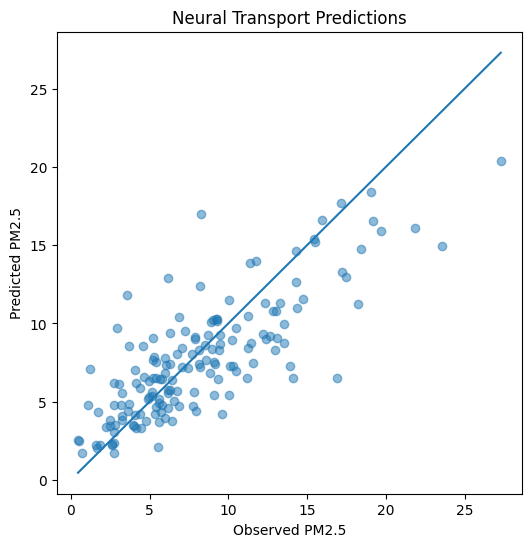

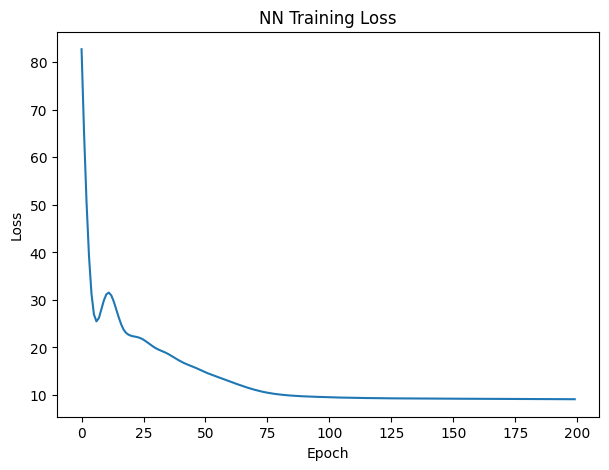


FEATURE IMPORTANCE
       Feature  Importance
0    pm25_lag1    0.261236
1    pm25_lag2    0.248346
2    spillover    0.239358
3   wind_speed    0.213172
4  temperature    0.204004
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.582
Model:                            OLS   Adj. R-squared:                  0.580
Method:                 Least Squares   F-statistic:                     221.0
Date:                Mon, 18 May 2026   Prob (F-statistic):          1.33e-147
Time:                        12:06:01   Log-Likelihood:                -2043.6
No. Observations:                 799   AIC:                             4099.
Df Residuals:                     793   BIC:                             4127.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std

In [ ]:
 
import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.metrics import mean_squared_error

from sklearn.linear_model import LinearRegression

import statsmodels.api as sm

import torch

import torch.nn as nn

import torch.optim as optim

 
df = pd.read_csv(
    
    "epa_pm25_transport.csv"
)

print(df.head())

print(df.shape)

 

df = df.dropna()

 

X = df[
    [
        "pm25_lag1",
        "pm25_lag2",
        "spillover",
        "wind_speed",
        "temperature"
    ]
].values

y = df["pm25"].values

 

X_train, X_test, y_train, y_test = train_test_split(
    
    X,
    
    y,
    
    test_size = 0.2,
    
    random_state = 123
)

 

baseline_model = LinearRegression()

baseline_model.fit(
    
    X_train,
    
    y_train
)

baseline_pred = baseline_model.predict(
    
    X_test
)

baseline_rmse = np.sqrt(
    
    mean_squared_error(
        
        y_test,
        
        baseline_pred
    )
)

print("\nBASELINE RMSE")

print(baseline_rmse)
 

X_train_tensor = torch.FloatTensor(
    X_train
)

y_train_tensor = torch.FloatTensor(
    y_train.reshape(-1,1)
)

X_test_tensor = torch.FloatTensor(
    X_test
)

 
class TransportNet(nn.Module):
    
    def __init__(self):
        
        super().__init__()
        
        self.network = nn.Sequential(
            
            nn.Linear(5,64),
            
            nn.ReLU(),
            
            nn.Linear(64,64),
            
            nn.ReLU(),
            
            nn.Linear(64,1)
        )
    
    def forward(self, x):
        
        return self.network(x)

model = TransportNet()

 

optimizer = optim.Adam(
    
    model.parameters(),
    
    lr = 0.001
)

loss_fn = nn.MSELoss()

 

epochs = 200

loss_history = []

for epoch in range(epochs):
    
    optimizer.zero_grad()
    
    predictions = model(
        X_train_tensor
    )
    
    loss = loss_fn(
        
        predictions,
        
        y_train_tensor
    )
    
    loss.backward()
    
    optimizer.step()
    
    loss_history.append(
        loss.item()
    )
    
    if epoch % 20 == 0:
        
        print(
            "Epoch:",
            epoch,
            "Loss:",
            loss.item()
        )
 

with torch.no_grad():
    
    nn_pred = model(
        X_test_tensor
    )

nn_pred = nn_pred.numpy().flatten()

 

nn_rmse = np.sqrt(
    
    mean_squared_error(
        
        y_test,
        
        nn_pred
    )
)

print("\nNN RMSE")

print(nn_rmse)

 

comparison = pd.DataFrame({
    
    "Model":[
        "Linear",
        "Neural"
    ],
    
    "RMSE":[
        baseline_rmse,
        nn_rmse
    ]
})

print(comparison)

 

plt.figure(figsize=(6,6))

plt.scatter(
    
    y_test,
    
    nn_pred,
    
    alpha=0.5
)

plt.xlabel("Observed PM2.5")

plt.ylabel("Predicted PM2.5")

plt.title("Neural Transport Predictions")

plt.plot(
    
    [
        y_test.min(),
        y_test.max()
    ],
    
    [
        y_test.min(),
        y_test.max()
    ]
)

plt.show()

 

plt.figure(figsize=(7,5))

plt.plot(
    loss_history
)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title("NN Training Loss")

plt.show()

 

weights_1 = model.network[0].weight.detach().numpy()

importance = np.mean(
    
    np.abs(weights_1),
    
    axis=0
)

importance_df = pd.DataFrame({
    
    "Feature":[
        
        "pm25_lag1",
        "pm25_lag2",
        "spillover",
        "wind_speed",
        "temperature"
    ],
    
    "Importance":importance
})

importance_df = importance_df.sort_values(
    
    "Importance",
    
    ascending=False
)

print("\nFEATURE IMPORTANCE")

print(importance_df)

 

X_sm = sm.add_constant(X)

ols_model = sm.OLS(
    
    y,
    
    X_sm
).fit()

print(ols_model.summary())

 

comparison.to_csv(
    
    "nn_vs_linear_results.csv",
    
    index=False
)

importance_df.to_csv(
    
    "nn_feature_importance.csv",
    
    index=False
)

print("\nFILES SAVED")
 

  county_name  date_local       pm25  pm25_lag1  pm25_lag2  spillover  \
0       Butte  2024-01-03   6.020834   9.041666  18.816667   5.707783   
1   Calaveras  2024-01-03   5.545454   5.647826   8.204166   5.993973   
2      Colusa  2024-01-03   7.274049  11.975000   6.673959   4.866218   
3      Fresno  2024-01-03   6.154816  14.259722  16.800000   7.330048   
4    Imperial  2024-01-03  13.918055   6.454167  11.497222   7.315705   

   wind_speed  temperature  
0   90.032292    45.605555  
1   79.631250    41.683333  
2   96.818750    47.778261  
3   99.992532    48.358333  
4  110.331250    53.416667  
(799, 8)

LINEAR MODEL
RMSE: 3.0769266429708875
R2: 0.6088581826218695
Epoch: 0 Loss: 130.8068389892578
Epoch: 25 Loss: 23.63194465637207
Epoch: 50 Loss: 16.69395637512207
Epoch: 75 Loss: 14.448445320129395
Epoch: 100 Loss: 12.237929344177246
Epoch: 125 Loss: 12.277278900146484
Epoch: 150 Loss: 10.85073184967041
Epoch: 175 Loss: 11.04975414276123
Epoch: 200 Loss: 10.518527030944824
Ep

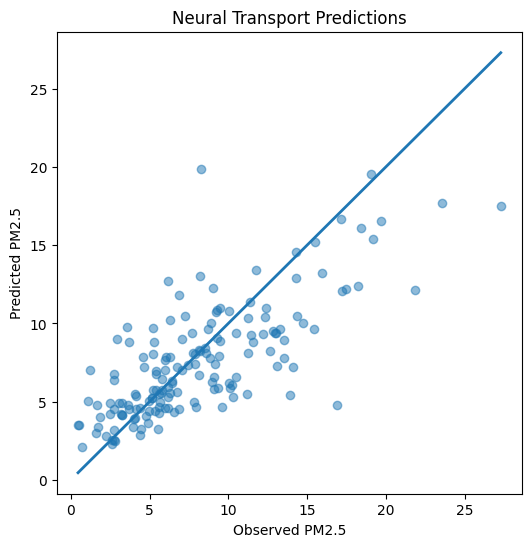

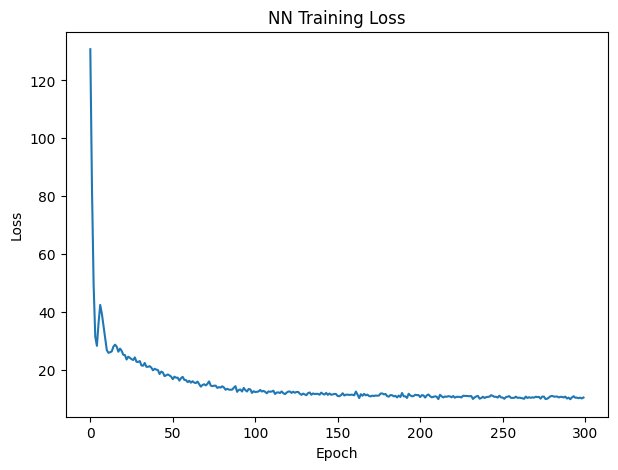


FEATURE IMPORTANCE
       Feature  Importance
0    pm25_lag1    0.413126
2    spillover    0.401677
3   wind_speed    0.001391
4  temperature    0.000317
1    pm25_lag2   -0.000086

COUNTY GENERALIZATION
Fold: 0 RMSE: 3.374413825731523
Fold: 1 RMSE: 2.799018630733921
Fold: 2 RMSE: 3.5422413191310826
Fold: 3 RMSE: 2.6959222299175805
Fold: 4 RMSE: 3.869884628587565

Mean County RMSE: 3.2562961268203336

TEMPORAL FORECASTING
Forecast RMSE: 3.7583455362667983

COUNTERFACTUAL ANALYSIS
Mean policy effect: 2.0129118478401407

SPATIAL RESIDUAL ANALYSIS
county_name
Butte              0.504081
Calaveras         -2.526632
Colusa             0.811042
Fresno             0.895382
Imperial           3.290142
Inyo               0.060521
Kern               1.244458
Kings              3.096014
Los Angeles        1.183782
Madera            -0.309878
Merced             0.674489
Mono              -2.398922
Orange            -0.178939
Placer            -0.057965
Riverside          0.521375
Sacramento      

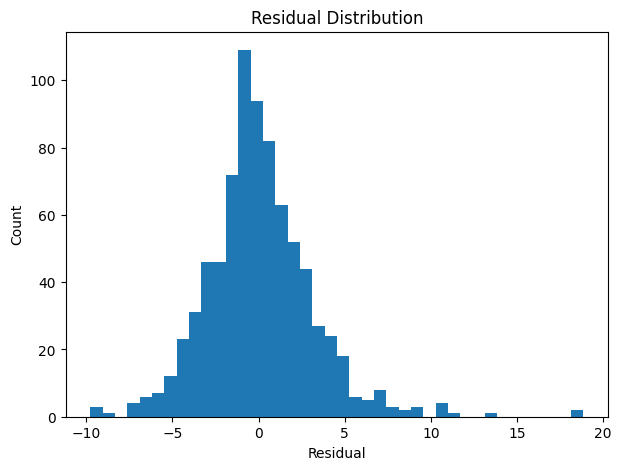


OLS SUMMARY
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.582
Model:                            OLS   Adj. R-squared:                  0.580
Method:                 Least Squares   F-statistic:                     221.0
Date:                Mon, 18 May 2026   Prob (F-statistic):          1.33e-147
Time:                        12:08:06   Log-Likelihood:                -2043.6
No. Observations:                 799   AIC:                             4099.
Df Residuals:                     793   BIC:                             4127.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.2758      1.044      0

In [ ]:
 

import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    GroupKFold
)

from sklearn.metrics import (
    mean_squared_error,
    r2_score
)

from sklearn.linear_model import LinearRegression

from sklearn.inspection import permutation_importance

import statsmodels.api as sm

import torch

import torch.nn as nn

import torch.optim as optim

from scipy.spatial.distance import pdist
from scipy.spatial.distance import squareform

 

df = pd.read_csv(
    
    "epa_pm25_transport.csv"
)

 

df = df.dropna()

print(df.head())

print(df.shape)

 

feature_cols = [
    
    "pm25_lag1",
    
    "pm25_lag2",
    
    "spillover",
    
    "wind_speed",
    
    "temperature"
]

X = df[
    feature_cols
].values

y = df["pm25"].values

 

X_train, X_test, y_train, y_test = train_test_split(
    
    X,
    
    y,
    
    test_size = 0.2,
    
    random_state = 123
)

linear_model = LinearRegression()

linear_model.fit(
    
    X_train,
    
    y_train
)

linear_pred = linear_model.predict(
    
    X_test
)

linear_rmse = np.sqrt(
    
    mean_squared_error(
        
        y_test,
        
        linear_pred
    )
)

linear_r2 = r2_score(
    
    y_test,
    
    linear_pred
)

print("\nLINEAR MODEL")

print("RMSE:", linear_rmse)

print("R2:", linear_r2)

 

X_train_tensor = torch.FloatTensor(
    X_train
)

y_train_tensor = torch.FloatTensor(
    y_train.reshape(-1,1)
)

X_test_tensor = torch.FloatTensor(
    X_test
)

 

class TransportNet(nn.Module):
    
    def __init__(self):
        
        super().__init__()
        
        self.network = nn.Sequential(
            
            nn.Linear(5,128),
            
            nn.ReLU(),
            
            nn.Dropout(0.2),
            
            nn.Linear(128,128),
            
            nn.ReLU(),
            
            nn.Dropout(0.2),
            
            nn.Linear(128,64),
            
            nn.ReLU(),
            
            nn.Linear(64,1)
        )
    
    def forward(self, x):
        
        return self.network(x)

model = TransportNet()

optimizer = optim.Adam(
    
    model.parameters(),
    
    lr = 0.001
)

loss_fn = nn.MSELoss()

 
epochs = 300

loss_history = []

for epoch in range(epochs):
    
    optimizer.zero_grad()
    
    pred = model(
        X_train_tensor
    )
    
    loss = loss_fn(
        
        pred,
        
        y_train_tensor
    )
    
    loss.backward()
    
    optimizer.step()
    
    loss_history.append(
        loss.item()
    )
    
    if epoch % 25 == 0:
        
        print(
            "Epoch:",
            epoch,
            "Loss:",
            loss.item()
        )

 

with torch.no_grad():
    
    nn_pred = model(
        X_test_tensor
    )

nn_pred = nn_pred.numpy().flatten()
 
 

nn_rmse = np.sqrt(
    
    mean_squared_error(
        
        y_test,
        
        nn_pred
    )
)

nn_r2 = r2_score(
    
    y_test,
    
    nn_pred
)

print("\nNEURAL MODEL")

print("RMSE:", nn_rmse)

print("R2:", nn_r2)

 

comparison = pd.DataFrame({
    
    "Model":[
        "Linear",
        "Neural"
    ],
    
    "RMSE":[
        linear_rmse,
        nn_rmse
    ],
    
    "R2":[
        linear_r2,
        nn_r2
    ]
})

print("\nMODEL COMPARISON")

print(comparison)
 

plt.figure(figsize=(6,6))

plt.scatter(
    
    y_test,
    
    nn_pred,
    
    alpha=0.5
)

plt.plot(
    
    [
        y_test.min(),
        y_test.max()
    ],
    
    [
        y_test.min(),
        y_test.max()
    ],
    
    linewidth=2
)

plt.xlabel("Observed PM2.5")

plt.ylabel("Predicted PM2.5")

plt.title("Neural Transport Predictions")

plt.show()

 

plt.figure(figsize=(7,5))

plt.plot(
    loss_history
)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title("NN Training Loss")

plt.show()

 

perm_importance = permutation_importance(
    
    linear_model,
    
    X_test,
    
    y_test,
    
    n_repeats=20,
    
    random_state=123
)

importance_df = pd.DataFrame({
    
    "Feature":feature_cols,
    
    "Importance":
        perm_importance.importances_mean
})

importance_df = importance_df.sort_values(
    
    "Importance",
    
    ascending=False
)

print("\nFEATURE IMPORTANCE")

print(importance_df)

 

print("\nCOUNTY GENERALIZATION")

groups = df["county_name"]

gkf = GroupKFold(
    n_splits=5
)

county_results = []

for fold, (train_idx, test_idx) in enumerate(
    
    gkf.split(X, y, groups)
):
    
    X_train_g = X[train_idx]
    X_test_g = X[test_idx]
    
    y_train_g = y[train_idx]
    y_test_g = y[test_idx]
    
    model_g = LinearRegression()
    
    model_g.fit(
        
        X_train_g,
        
        y_train_g
    )
    
    pred_g = model_g.predict(
        X_test_g
    )
    
    rmse_g = np.sqrt(
        
        mean_squared_error(
            
            y_test_g,
            
            pred_g
        )
    )
    
    county_results.append(
        rmse_g
    )
    
    print(
        "Fold:",
        fold,
        "RMSE:",
        rmse_g
    )

print(
    "\nMean County RMSE:",
    np.mean(county_results)
)
 

print("\nTEMPORAL FORECASTING")

df_sorted = df.sort_values(
    "date_local"
)

split_idx = int(
    0.8 * len(df_sorted)
)

train_df = df_sorted.iloc[:split_idx]

test_df = df_sorted.iloc[split_idx:]

X_train_t = train_df[
    feature_cols
].values

X_test_t = test_df[
    feature_cols
].values

y_train_t = train_df["pm25"].values

y_test_t = test_df["pm25"].values

forecast_model = LinearRegression()

forecast_model.fit(
    
    X_train_t,
    
    y_train_t
)

forecast_pred = forecast_model.predict(
    
    X_test_t
)

forecast_rmse = np.sqrt(
    
    mean_squared_error(
        
        y_test_t,
        
        forecast_pred
    )
)

print(
    "Forecast RMSE:",
    forecast_rmse
)

 

print("\nCOUNTERFACTUAL ANALYSIS")

counterfactual = X.copy()

# reduce spillover by 50%

counterfactual[:,2] = (
    
    counterfactual[:,2] * 0.5
)

counterfactual_pred = linear_model.predict(
    
    counterfactual
)

policy_effect = np.mean(
    
    y - counterfactual_pred
)

print(
    "Mean policy effect:",
    policy_effect
)

 

print("\nSPATIAL RESIDUAL ANALYSIS")

full_linear_pred = linear_model.predict(
    X
)

df["residuals"] = (
    
    y
    
    - full_linear_pred
)

county_residuals = df.groupby(
    
    "county_name"
)["residuals"].mean()

print(county_residuals)

 

plt.figure(figsize=(7,5))

plt.hist(
    
    df["residuals"],
    
    bins=40
)

plt.xlabel("Residual")

plt.ylabel("Count")

plt.title("Residual Distribution")

plt.show()

 

X_sm = sm.add_constant(X)

ols_model = sm.OLS(
    
    y,
    
    X_sm
).fit()

print("\nOLS SUMMARY")

print(ols_model.summary())

 
ci = ols_model.conf_int()

print("\nCONFIDENCE INTERVALS")

print(ci)

 
comparison.to_csv(
    
    "model_comparison.csv",
    
    index=False
)

importance_df.to_csv(
    
    "feature_importance.csv",
    
    index=False
)

df.to_csv(
    
    "epa_transport_predictions.csv",
    
    index=False
)

print("\nFILES SAVED")

 

  county_name  date_local       pm25  pm25_lag1  pm25_lag2  spillover  \
0       Butte  2024-01-03   6.020834   9.041666  18.816667   5.707783   
1   Calaveras  2024-01-03   5.545454   5.647826   8.204166   5.993973   
2      Colusa  2024-01-03   7.274049  11.975000   6.673959   4.866218   
3      Fresno  2024-01-03   6.154816  14.259722  16.800000   7.330048   
4    Imperial  2024-01-03  13.918055   6.454167  11.497222   7.315705   

   wind_speed  temperature  
0   90.032292    45.605555  
1   79.631250    41.683333  
2   96.818750    47.778261  
3   99.992532    48.358333  
4  110.331250    53.416667  
(799, 8)

LINEAR MODEL
RMSE: 3.0769266429708875
R2: 0.6088581826218695
Epoch: 0 Loss: 65.21122741699219
Epoch: 25 Loss: 17.54775619506836
Epoch: 50 Loss: 13.183401107788086
Epoch: 75 Loss: 11.94714641571045
Epoch: 100 Loss: 11.096211433410645
Epoch: 125 Loss: 10.906192779541016
Epoch: 150 Loss: 10.798717498779297
Epoch: 175 Loss: 10.312329292297363
Epoch: 200 Loss: 9.695157051086426
E

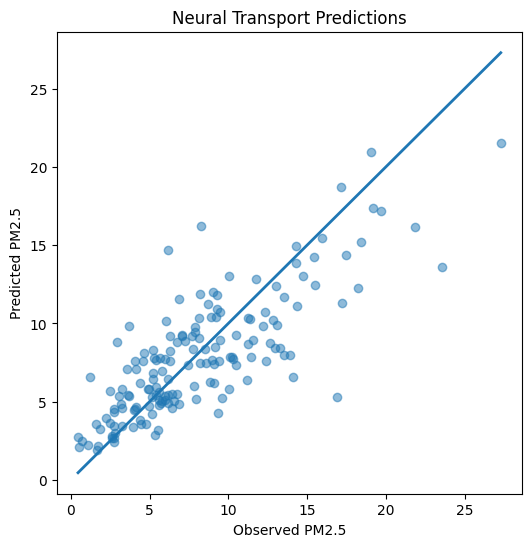

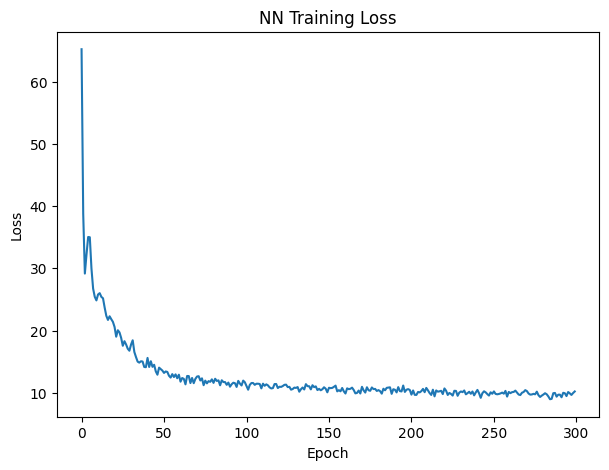


FEATURE IMPORTANCE
       Feature  Importance
0    pm25_lag1    0.413126
2    spillover    0.401677
3   wind_speed    0.001391
4  temperature    0.000317
1    pm25_lag2   -0.000086

COUNTY GENERALIZATION
Fold: 0 RMSE: 3.374413825731523
Fold: 1 RMSE: 2.799018630733921
Fold: 2 RMSE: 3.5422413191310826
Fold: 3 RMSE: 2.6959222299175805
Fold: 4 RMSE: 3.869884628587565

Mean County RMSE: 3.2562961268203336

TEMPORAL FORECASTING
Forecast RMSE: 3.7583455362667983

COUNTERFACTUAL ANALYSIS
Mean policy effect: 2.0129118478401407

SPATIAL RESIDUAL ANALYSIS
county_name
Butte              0.504081
Calaveras         -2.526632
Colusa             0.811042
Fresno             0.895382
Imperial           3.290142
Inyo               0.060521
Kern               1.244458
Kings              3.096014
Los Angeles        1.183782
Madera            -0.309878
Merced             0.674489
Mono              -2.398922
Orange            -0.178939
Placer            -0.057965
Riverside          0.521375
Sacramento      

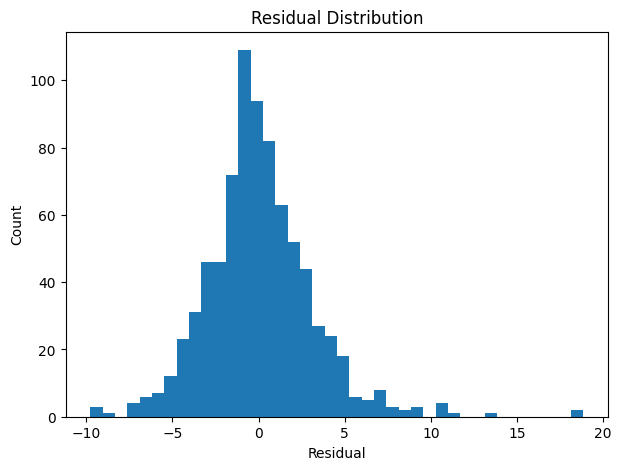


OLS SUMMARY
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.582
Model:                            OLS   Adj. R-squared:                  0.580
Method:                 Least Squares   F-statistic:                     221.0
Date:                Mon, 18 May 2026   Prob (F-statistic):          1.33e-147
Time:                        12:08:41   Log-Likelihood:                -2043.6
No. Observations:                 799   AIC:                             4099.
Df Residuals:                     793   BIC:                             4127.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.2758      1.044      0

In [ ]:
 

import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    GroupKFold
)

from sklearn.metrics import (
    mean_squared_error,
    r2_score
)

from sklearn.linear_model import LinearRegression

from sklearn.inspection import permutation_importance

import statsmodels.api as sm

import torch

import torch.nn as nn

import torch.optim as optim

from scipy.spatial.distance import pdist
from scipy.spatial.distance import squareform

 

df = pd.read_csv(
    
    "epa_pm25_transport.csv"
)

 
df = df.dropna()

print(df.head())

print(df.shape)

 
 

feature_cols = [
    
    "pm25_lag1",
    
    "pm25_lag2",
    
    "spillover",
    
    "wind_speed",
    
    "temperature"
]

X = df[
    feature_cols
].values

y = df["pm25"].values

 

X_train, X_test, y_train, y_test = train_test_split(
    
    X,
    
    y,
    
    test_size = 0.2,
    
    random_state = 123
)

linear_model = LinearRegression()

linear_model.fit(
    
    X_train,
    
    y_train
)

linear_pred = linear_model.predict(
    
    X_test
)

linear_rmse = np.sqrt(
    
    mean_squared_error(
        
        y_test,
        
        linear_pred
    )
)

linear_r2 = r2_score(
    
    y_test,
    
    linear_pred
)

print("\nLINEAR MODEL")

print("RMSE:", linear_rmse)

print("R2:", linear_r2)

 

X_train_tensor = torch.FloatTensor(
    X_train
)

y_train_tensor = torch.FloatTensor(
    y_train.reshape(-1,1)
)

X_test_tensor = torch.FloatTensor(
    X_test
)

 

class TransportNet(nn.Module):
    
    def __init__(self):
        
        super().__init__()
        
        self.network = nn.Sequential(
            
            nn.Linear(5,128),
            
            nn.ReLU(),
            
            nn.Dropout(0.2),
            
            nn.Linear(128,128),
            
            nn.ReLU(),
            
            nn.Dropout(0.2),
            
            nn.Linear(128,64),
            
            nn.ReLU(),
            
            nn.Linear(64,1)
        )
    
    def forward(self, x):
        
        return self.network(x)

model = TransportNet()

optimizer = optim.Adam(
    
    model.parameters(),
    
    lr = 0.001
)

loss_fn = nn.MSELoss()

 

epochs = 300

loss_history = []

for epoch in range(epochs):
    
    optimizer.zero_grad()
    
    pred = model(
        X_train_tensor
    )
    
    loss = loss_fn(
        
        pred,
        
        y_train_tensor
    )
    
    loss.backward()
    
    optimizer.step()
    
    loss_history.append(
        loss.item()
    )
    
    if epoch % 25 == 0:
        
        print(
            "Epoch:",
            epoch,
            "Loss:",
            loss.item()
        )

 

with torch.no_grad():
    
    nn_pred = model(
        X_test_tensor
    )

nn_pred = nn_pred.numpy().flatten()



nn_rmse = np.sqrt(
    
    mean_squared_error(
        
        y_test,
        
        nn_pred
    )
)

nn_r2 = r2_score(
    
    y_test,
    
    nn_pred
)

print("\nNEURAL MODEL")

print("RMSE:", nn_rmse)

print("R2:", nn_r2)

 

comparison = pd.DataFrame({
    
    "Model":[
        "Linear",
        "Neural"
    ],
    
    "RMSE":[
        linear_rmse,
        nn_rmse
    ],
    
    "R2":[
        linear_r2,
        nn_r2
    ]
})

print("\nMODEL COMPARISON")

print(comparison)

 

plt.figure(figsize=(6,6))

plt.scatter(
    
    y_test,
    
    nn_pred,
    
    alpha=0.5
)

plt.plot(
    
    [
        y_test.min(),
        y_test.max()
    ],
    
    [
        y_test.min(),
        y_test.max()
    ],
    
    linewidth=2
)

plt.xlabel("Observed PM2.5")

plt.ylabel("Predicted PM2.5")

plt.title("Neural Transport Predictions")

plt.show()

 

plt.figure(figsize=(7,5))

plt.plot(
    loss_history
)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title("NN Training Loss")

plt.show()

 

perm_importance = permutation_importance(
    
    linear_model,
    
    X_test,
    
    y_test,
    
    n_repeats=20,
    
    random_state=123
)

importance_df = pd.DataFrame({
    
    "Feature":feature_cols,
    
    "Importance":
        perm_importance.importances_mean
})

importance_df = importance_df.sort_values(
    
    "Importance",
    
    ascending=False
)

print("\nFEATURE IMPORTANCE")

print(importance_df)

 

print("\nCOUNTY GENERALIZATION")

groups = df["county_name"]

gkf = GroupKFold(
    n_splits=5
)

county_results = []

for fold, (train_idx, test_idx) in enumerate(
    
    gkf.split(X, y, groups)
):
    
    X_train_g = X[train_idx]
    X_test_g = X[test_idx]
    
    y_train_g = y[train_idx]
    y_test_g = y[test_idx]
    
    model_g = LinearRegression()
    
    model_g.fit(
        
        X_train_g,
        
        y_train_g
    )
    
    pred_g = model_g.predict(
        X_test_g
    )
    
    rmse_g = np.sqrt(
        
        mean_squared_error(
            
            y_test_g,
            
            pred_g
        )
    )
    
    county_results.append(
        rmse_g
    )
    
    print(
        "Fold:",
        fold,
        "RMSE:",
        rmse_g
    )

print(
    "\nMean County RMSE:",
    np.mean(county_results)
)

 
print("\nTEMPORAL FORECASTING")

df_sorted = df.sort_values(
    "date_local"
)

split_idx = int(
    0.8 * len(df_sorted)
)

train_df = df_sorted.iloc[:split_idx]

test_df = df_sorted.iloc[split_idx:]

X_train_t = train_df[
    feature_cols
].values

X_test_t = test_df[
    feature_cols
].values

y_train_t = train_df["pm25"].values

y_test_t = test_df["pm25"].values

forecast_model = LinearRegression()

forecast_model.fit(
    
    X_train_t,
    
    y_train_t
)

forecast_pred = forecast_model.predict(
    
    X_test_t
)

forecast_rmse = np.sqrt(
    
    mean_squared_error(
        
        y_test_t,
        
        forecast_pred
    )
)

print(
    "Forecast RMSE:",
    forecast_rmse
)
 

print("\nCOUNTERFACTUAL ANALYSIS")

counterfactual = X.copy()

# reduce spillover by 50%

counterfactual[:,2] = (
    
    counterfactual[:,2] * 0.5
)

counterfactual_pred = linear_model.predict(
    
    counterfactual
)

policy_effect = np.mean(
    
    y - counterfactual_pred
)

print(
    "Mean policy effect:",
    policy_effect
)

 

print("\nSPATIAL RESIDUAL ANALYSIS")

full_linear_pred = linear_model.predict(
    X
)

df["residuals"] = (
    
    y
    
    - full_linear_pred
)

county_residuals = df.groupby(
    
    "county_name"
)["residuals"].mean()

print(county_residuals)
 

plt.figure(figsize=(7,5))

plt.hist(
    
    df["residuals"],
    
    bins=40
)

plt.xlabel("Residual")

plt.ylabel("Count")

plt.title("Residual Distribution")

plt.show()

 

X_sm = sm.add_constant(X)

ols_model = sm.OLS(
    
    y,
    
    X_sm
).fit()

print("\nOLS SUMMARY")

print(ols_model.summary())

 

ci = ols_model.conf_int()

print("\nCONFIDENCE INTERVALS")

print(ci)

 

comparison.to_csv(
    
    "model_comparison.csv",
    
    index=False
)

importance_df.to_csv(
    
    "feature_importance.csv",
    
    index=False
)

df.to_csv(
    
    "epa_transport_predictions.csv",
    
    index=False
)

print("\nFILES SAVED")

 

In [ ]:
 
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from sklearn.linear_model import LinearRegression
feature_sets = {
    
    "lags_only":[
        "pm25_lag1",
        "pm25_lag2"
    ],
    
    "lags_weather":[
        "pm25_lag1",
        "pm25_lag2",
        "wind_speed",
        "temperature"
    ],
    
    "full_model":[
        "pm25_lag1",
        "pm25_lag2",
        "spillover",
        "wind_speed",
        "temperature"
    ]
}

ablation_results = []

for name, cols in feature_sets.items():
    
    X_ab = df[cols].values
    
    y_ab = df["pm25"].values
    
    X_train_ab, X_test_ab, y_train_ab, y_test_ab = train_test_split(
        
        X_ab,
        
        y_ab,
        
        test_size=0.2,
        
        random_state=123
    )
    
    model_ab = LinearRegression()
    
    model_ab.fit(
        
        X_train_ab,
        
        y_train_ab
    )
    
    pred_ab = model_ab.predict(
        X_test_ab
    )
    
    rmse_ab = np.sqrt(
        
        mean_squared_error(
            
            y_test_ab,
            
            pred_ab
        )
    )
    
    r2_ab = r2_score(
        
        y_test_ab,
        
        pred_ab
    )
    
    ablation_results.append({
        
        "model":name,
        
        "rmse":rmse_ab,
        
        "r2":r2_ab
    })

ablation_results = pd.DataFrame(
    ablation_results
)

print(ablation_results)

          model      rmse        r2
0     lags_only  3.664858  0.445101
1  lags_weather  3.644369  0.451288
2    full_model  3.076927  0.608858


In [ ]:
 

n_boot = 100

boot_betas = []

for b in range(n_boot):
    
    sample_idx = np.random.choice(
        
        len(df),
        
        size=len(df),
        
        replace=True
    )
    
    X_boot = X[sample_idx]
    
    y_boot = y[sample_idx]
    
    model_boot = LinearRegression()
    
    model_boot.fit(
        
        X_boot,
        
        y_boot
    )
    
    boot_betas.append(
        
        model_boot.coef_[2]
    )

boot_betas = np.array(
    boot_betas
)

print(
    
    np.percentile(
        boot_betas,
        [2.5,97.5]
    )
)

[0.42105034 0.5524976 ]


       Feature  Importance
0    pm25_lag1    0.414741
2    spillover    0.397199
3   wind_speed    0.001358
4  temperature    0.000392
1    pm25_lag2   -0.000089


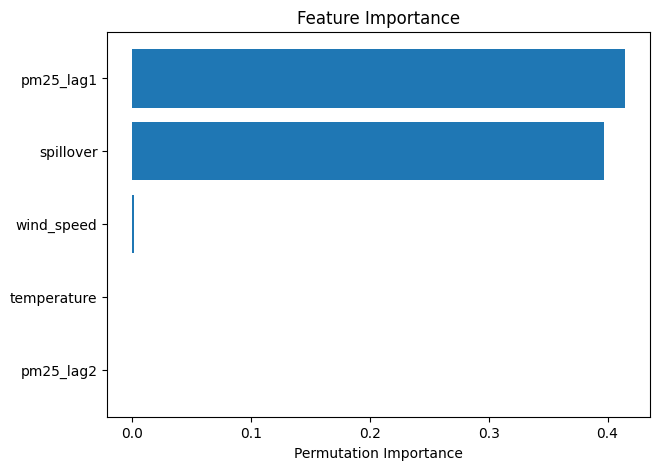

In [ ]:
 

from sklearn.inspection import permutation_importance

perm = permutation_importance(
    
    linear_model,
    
    X_test,
    
    y_test,
    
    n_repeats = 30,
    
    random_state = 123
)

importance_df = pd.DataFrame({
    
    "Feature":feature_cols,
    
    "Importance":
        perm.importances_mean
})

importance_df = importance_df.sort_values(
    
    "Importance",
    
    ascending=False
)

print(importance_df)

 

plt.figure(figsize=(7,5))

plt.barh(
    
    importance_df["Feature"],
    
    importance_df["Importance"]
)

plt.xlabel("Permutation Importance")

plt.title("Feature Importance")

plt.gca().invert_yaxis()

plt.show()

  county_name   latitude   longitude
0       Butte  39.761680 -121.840470
1   Calaveras  38.201850 -120.680277
2      Colusa  39.105851 -122.139249
3      Fresno  36.777846 -119.838313
4    Imperial  32.813944 -115.527748
  county_name  date_local       pm25  pm25_lag1  pm25_lag2  spillover  \
0       Butte  2024-01-03   6.020834   9.041666  18.816667   5.707783   
1   Calaveras  2024-01-03   5.545454   5.647826   8.204166   5.993973   
2      Colusa  2024-01-03   7.274049  11.975000   6.673959   4.866218   
3      Fresno  2024-01-03   6.154816  14.259722  16.800000   7.330048   
4    Imperial  2024-01-03  13.918055   6.454167  11.497222   7.315705   

   wind_speed  temperature  directional_spillover  
0   90.032292    45.605555               5.205919  
1   79.631250    41.683333               5.019760  
2   96.818750    47.778261               4.954014  
3   99.992532    48.358333               4.693389  
4  110.331250    53.416667               6.704756  

DIRECTIONAL MODEL
RMSE: 3.

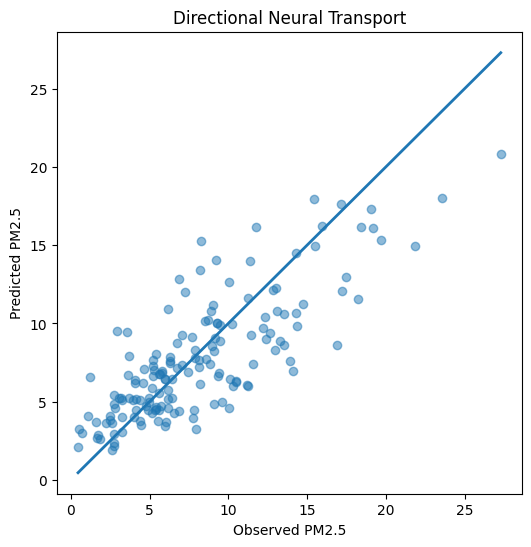

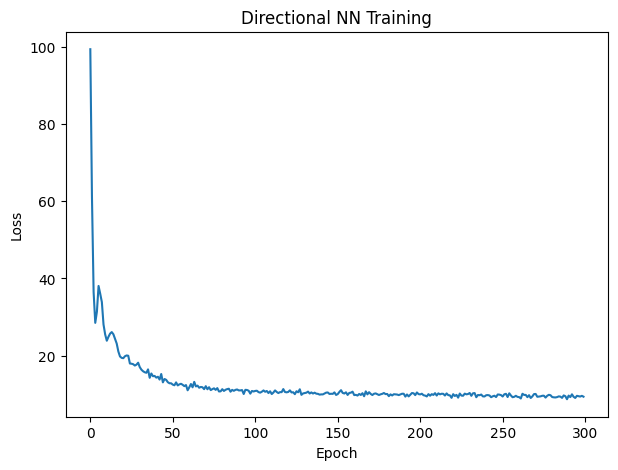


COEFFICIENTS
                 Feature  Coefficient
0              pm25_lag1     0.424915
1              pm25_lag2     0.008516
2              spillover     0.369220
3  directional_spillover     0.247622
4             wind_speed    -0.003471
5            temperature     0.014179

TRANSPORT REDUCTION EFFECT
1.0129916564262553

COUNTY TRANSPORT
county_name
Butte              7.121602
Calaveras          7.353476
Colusa             6.947560
Fresno             7.257033
Imperial           8.287497
Inyo               7.601215
Kern               7.921937
Kings              7.033469
Los Angeles        7.699212
Madera             7.331689
Merced             7.052582
Mono               7.908451
Orange             8.053918
Placer             7.147808
Riverside          8.647449
Sacramento         7.143288
San Benito         7.508955
San Bernardino     8.502332
San Diego          9.408235
San Joaquin        6.922283
San Luis Obispo    7.604418
Santa Barbara      7.688353
Santa Clara        7.436933

In [ ]:
 

import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_squared_error,
    r2_score
)

from sklearn.model_selection import train_test_split

from scipy.spatial.distance import cdist

import torch

import torch.nn as nn

import torch.optim as optim

 

df = pd.read_csv(
    
    "epa_pm25_transport.csv"
)

df = df.dropna()

 

county_coords = pd.read_csv(
    
    "county_coordinates.csv"
)

print(county_coords.head())

 

county_order = county_coords[
    "county_name"
].values

 

coords = county_coords[
    [
        "latitude",
        "longitude"
    ]
].values

distance_matrix = cdist(
    
    coords,
    
    coords
)

 

def directional_kernel(
    
    dist,
    
    wind_speed,
    
    sigma=1.5
):
    
    return np.exp(
        
        -(dist**2) /
        
        (2*sigma**2)
    ) * (
        
        1
        
        + 0.1*wind_speed
    )

 

spillover_list = []

unique_dates = sorted(
    
    df["date_local"].unique()
)

for d in unique_dates:
    
    day_df = df[
        
        df["date_local"] == d
    ]
    
 
    
    aligned = pd.DataFrame({
        
        "county_name":county_order
    })
    
    aligned = aligned.merge(
        
        day_df,
        
        on="county_name",
        
        how="left"
    )
    
    pm = aligned[
        "pm25"
    ].values
    
    wind = aligned[
        "wind_speed"
    ].values
    
    spill = np.zeros(
        len(pm)
    )
    
    for i in range(len(pm)):
        
        weights = directional_kernel(
            
            distance_matrix[i],
            
            np.nanmean(wind)
        )
        
        weights[i] = 0
        
        weights = weights / np.sum(weights)
        
        spill[i] = np.nansum(
            
            weights * pm
        )
    
    aligned[
        "directional_spillover"
    ] = spill
    
    spillover_list.append(
        aligned
    )

directional_df = pd.concat(
    
    spillover_list
)

 

print(
    directional_df.head()
)

 

feature_cols = [
    
    "pm25_lag1",
    
    "pm25_lag2",
    
    "spillover",
    
    "directional_spillover",
    
    "wind_speed",
    
    "temperature"
]

directional_df = directional_df.dropna()

X = directional_df[
    feature_cols
].values

y = directional_df[
    "pm25"
].values

 

X_train, X_test, y_train, y_test = train_test_split(
    
    X,
    
    y,
    
    test_size=0.2,
    
    random_state=123
)

 

directional_model = LinearRegression()

directional_model.fit(
    
    X_train,
    
    y_train
)

directional_pred = directional_model.predict(
    
    X_test
)

directional_rmse = np.sqrt(
    
    mean_squared_error(
        
        y_test,
        
        directional_pred
    )
)

directional_r2 = r2_score(
    
    y_test,
    
    directional_pred
)

print("\nDIRECTIONAL MODEL")

print("RMSE:", directional_rmse)

print("R2:", directional_r2)

 

X_train_tensor = torch.FloatTensor(
    X_train
)

y_train_tensor = torch.FloatTensor(
    y_train.reshape(-1,1)
)

X_test_tensor = torch.FloatTensor(
    X_test
)

 

class DirectionalTransportNet(nn.Module):
    
    def __init__(self):
        
        super().__init__()
        
        self.network = nn.Sequential(
            
            nn.Linear(6,128),
            
            nn.ReLU(),
            
            nn.Dropout(0.2),
            
            nn.Linear(128,128),
            
            nn.ReLU(),
            
            nn.Dropout(0.2),
            
            nn.Linear(128,64),
            
            nn.ReLU(),
            
            nn.Linear(64,1)
        )
    
    def forward(self, x):
        
        return self.network(x)

model = DirectionalTransportNet()

optimizer = optim.Adam(
    
    model.parameters(),
    
    lr=0.001
)

loss_fn = nn.MSELoss()

 

epochs = 300

loss_history = []

for epoch in range(epochs):
    
    optimizer.zero_grad()
    
    pred = model(
        X_train_tensor
    )
    
    loss = loss_fn(
        
        pred,
        
        y_train_tensor
    )
    
    loss.backward()
    
    optimizer.step()
    
    loss_history.append(
        loss.item()
    )
    
    if epoch % 25 == 0:
        
        print(
            "Epoch:",
            epoch,
            "Loss:",
            loss.item()
        )

 

with torch.no_grad():
    
    nn_pred = model(
        X_test_tensor
    )

nn_pred = nn_pred.numpy().flatten()

 

nn_rmse = np.sqrt(
    
    mean_squared_error(
        
        y_test,
        
        nn_pred
    )
)

nn_r2 = r2_score(
    
    y_test,
    
    nn_pred
)

print("\nNN DIRECTIONAL MODEL")

print("RMSE:", nn_rmse)

print("R2:", nn_r2)

 

comparison = pd.DataFrame({
    
    "Model":[
        
        "Directional Linear",
        
        "Directional Neural"
    ],
    
    "RMSE":[
        
        directional_rmse,
        
        nn_rmse
    ],
    
    "R2":[
        
        directional_r2,
        
        nn_r2
    ]
})

print("\nMODEL COMPARISON")

print(comparison)

 

plt.figure(figsize=(6,6))

plt.scatter(
    
    y_test,
    
    nn_pred,
    
    alpha=0.5
)

plt.plot(
    
    [
        y_test.min(),
        y_test.max()
    ],
    
    [
        y_test.min(),
        y_test.max()
    ],
    
    linewidth=2
)

plt.xlabel("Observed PM2.5")

plt.ylabel("Predicted PM2.5")

plt.title("Directional Neural Transport")

plt.show()

 

plt.figure(figsize=(7,5))

plt.plot(
    loss_history
)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title("Directional NN Training")

plt.show()

 

coef_df = pd.DataFrame({
    
    "Feature":feature_cols,
    
    "Coefficient":
        directional_model.coef_
})

print("\nCOEFFICIENTS")

print(coef_df)

 

counterfactual = X.copy()

# reduce directional spillover

counterfactual[:,3] = (
    
    counterfactual[:,3] * 0.5
)

counter_pred = directional_model.predict(
    
    counterfactual
)

policy_effect = np.mean(
    
    y
    
    - counter_pred
)

print("\nTRANSPORT REDUCTION EFFECT")

print(policy_effect)

 

county_effects = directional_df.groupby(
    
    "county_name"
)[
    "directional_spillover"
].mean()

print("\nCOUNTY TRANSPORT")

print(county_effects)

 

comparison.to_csv(
    
    "directional_model_comparison.csv",
    
    index=False
)

coef_df.to_csv(
    
    "directional_coefficients.csv",
    
    index=False
)

directional_df.to_csv(
    
    "directional_transport_predictions.csv",
    
    index=False
)

print("\nFILES SAVED")

 

  county_name  date_local       pm25  pm25_lag1  pm25_lag2  spillover  \
0       Butte  2024-01-03   6.020834   9.041666  18.816667   5.707783   
1   Calaveras  2024-01-03   5.545454   5.647826   8.204166   5.993973   
2      Colusa  2024-01-03   7.274049  11.975000   6.673959   4.866218   
3      Fresno  2024-01-03   6.154816  14.259722  16.800000   7.330048   
4    Imperial  2024-01-03  13.918055   6.454167  11.497222   7.315705   

   wind_speed  temperature  anisotropic_spillover  
0   90.032292    45.605555               0.910597  
1   79.631250    41.683333               2.423856  
2   96.818750    47.778261               5.198742  
3   99.992532    48.358333               2.730297  
4  110.331250    53.416667               3.038046  

ANISOTROPIC MODEL
RMSE: 3.029503231888405
R2: 0.6208222851881335

COEFFICIENTS
                 Feature  Coefficient
0              pm25_lag1     0.432941
1              pm25_lag2     0.005710
2              spillover     0.458006
3  anisotropic_sp

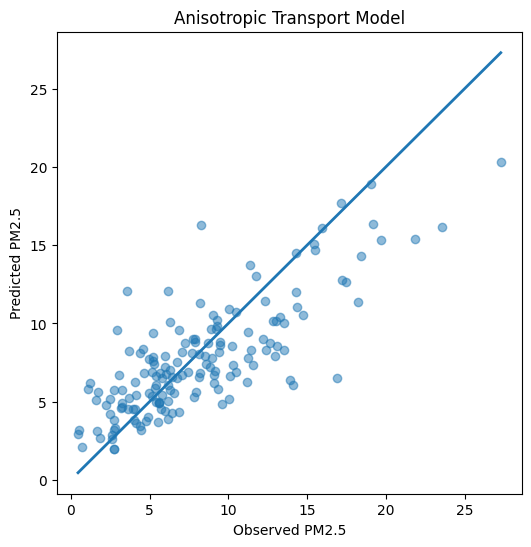

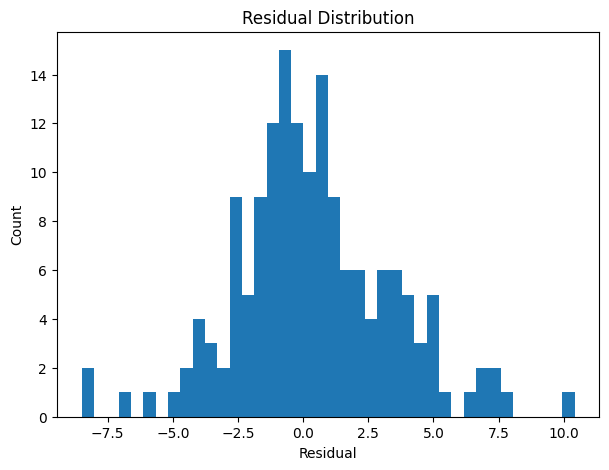


MODEL COMPARISON
         Model      RMSE        R2
0    Isotropic  3.076927  0.608858
1  Anisotropic  3.029503  0.620822


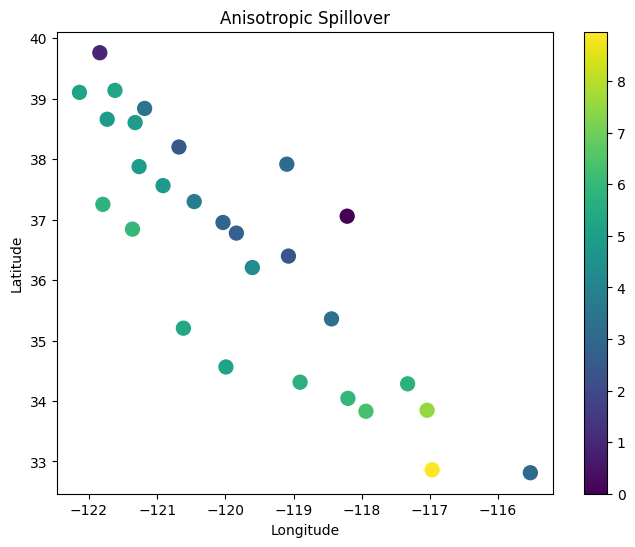


FILES SAVED


In [ ]:
 

import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_squared_error,
    r2_score
)

from sklearn.model_selection import train_test_split

from scipy.spatial.distance import cdist

 

df = pd.read_csv(
    
    "epa_pm25_transport.csv"
)

coords_df = pd.read_csv(
    
    "county_coordinates.csv"
)

df = df.dropna()

 

county_order = coords_df[
    "county_name"
].values

 

coords = coords_df[
    [
        "longitude",
        "latitude"
    ]
].values

 

distance_matrix = cdist(
    
    coords,
    
    coords
)

 

direction_matrix = np.zeros(
    
    (
        len(coords),
        len(coords)
    )
)

for i in range(len(coords)):
    
    for j in range(len(coords)):
        
        dx = (
            
            coords[j,0]
            
            - 
            
            coords[i,0]
        )
        
        dy = (
            
            coords[j,1]
            
            - 
            
            coords[i,1]
        )
        
        direction_matrix[i,j] = np.arctan2(
            
            dy,
            
            dx
        )

 

# approximate west -> east transport

wind_angle = np.pi / 4

 

def anisotropic_kernel(
    
    distance,
    
    direction,
    
    wind_angle,
    
    sigma = 1.5
):
    
    gaussian_part = np.exp(
        
        -(distance**2) /
        
        (2*sigma**2)
    )
    
    directional_part = np.maximum(
        
        0,
        
        np.cos(
            
            direction
            
            - 
            
            wind_angle
        )
    )
    
    return (
        
        gaussian_part
        
        * directional_part
    )

 

anisotropic_results = []

unique_dates = sorted(
    
    df["date_local"].unique()
)

for d in unique_dates:
    
    day_df = df[
        
        df["date_local"] == d
    ]
    
    aligned = pd.DataFrame({
        
        "county_name":county_order
    })
    
    aligned = aligned.merge(
        
        day_df,
        
        on="county_name",
        
        how="left"
    )
    
    aligned = aligned.sort_values(
        "county_name"
    )
    
    pm = aligned[
        "pm25"
    ].values
    
    spill = np.zeros(
        len(pm)
    )
    
    for i in range(len(pm)):
        
        weights = anisotropic_kernel(
            
            distance_matrix[i],
            
            direction_matrix[i],
            
            wind_angle
        )
        
        weights[i] = 0
        
        weight_sum = np.nansum(
            weights
        )
        
        if weight_sum > 0:
            
            weights = (
                
                weights
                
                / weight_sum
            )
        
        spill[i] = np.nansum(
            
            weights * pm
        )
    
    aligned[
        "anisotropic_spillover"
    ] = spill
    
    anisotropic_results.append(
        aligned
    )

anisotropic_df = pd.concat(
    
    anisotropic_results
)

 

print(
    anisotropic_df.head()
)

 

feature_cols = [
    
    "pm25_lag1",
    
    "pm25_lag2",
    
    "spillover",
    
    "anisotropic_spillover",
    
    "wind_speed",
    
    "temperature"
]

anisotropic_df = anisotropic_df.dropna()

X = anisotropic_df[
    feature_cols
].values

y = anisotropic_df[
    "pm25"
].values

 

X_train, X_test, y_train, y_test = train_test_split(
    
    X,
    
    y,
    
    test_size = 0.2,
    
    random_state = 123
)

 

anisotropic_model = LinearRegression()

anisotropic_model.fit(
    
    X_train,
    
    y_train
)

pred = anisotropic_model.predict(
    
    X_test
)
 

rmse = np.sqrt(
    
    mean_squared_error(
        
        y_test,
        
        pred
    )
)

r2 = r2_score(
    
    y_test,
    
    pred
)

print("\nANISOTROPIC MODEL")

print("RMSE:", rmse)

print("R2:", r2)

 

coef_df = pd.DataFrame({
    
    "Feature":feature_cols,
    
    "Coefficient":
        anisotropic_model.coef_
})

print("\nCOEFFICIENTS")

print(coef_df)

 

plt.figure(figsize=(6,6))

plt.scatter(
    
    y_test,
    
    pred,
    
    alpha=0.5
)

plt.plot(
    
    [
        y_test.min(),
        y_test.max()
    ],
    
    [
        y_test.min(),
        y_test.max()
    ],
    
    linewidth=2
)

plt.xlabel("Observed PM2.5")

plt.ylabel("Predicted PM2.5")

plt.title("Anisotropic Transport Model")

plt.show()

 

residuals = (
    
    y_test
    
    - 
    
    pred
)

plt.figure(figsize=(7,5))

plt.hist(
    
    residuals,
    
    bins=40
)

plt.xlabel("Residual")

plt.ylabel("Count")

plt.title("Residual Distribution")

plt.show()

 

iso_model = LinearRegression()

X_iso = anisotropic_df[
    [
        "pm25_lag1",
        "pm25_lag2",
        "spillover",
        "wind_speed",
        "temperature"
    ]
].values

X_train_iso, X_test_iso, y_train_iso, y_test_iso = train_test_split(
    
    X_iso,
    
    y,
    
    test_size=0.2,
    
    random_state=123
)

iso_model.fit(
    
    X_train_iso,
    
    y_train_iso
)

iso_pred = iso_model.predict(
    
    X_test_iso
)

iso_rmse = np.sqrt(
    
    mean_squared_error(
        
        y_test_iso,
        
        iso_pred
    )
)

iso_r2 = r2_score(
    
    y_test_iso,
    
    iso_pred
)

comparison = pd.DataFrame({
    
    "Model":[
        
        "Isotropic",
        
        "Anisotropic"
    ],
    
    "RMSE":[
        
        iso_rmse,
        
        rmse
    ],
    
    "R2":[
        
        iso_r2,
        
        r2
    ]
})

print("\nMODEL COMPARISON")

print(comparison)

 

example_day = anisotropic_df[
    
    anisotropic_df["date_local"]
    
    ==
    
    anisotropic_df["date_local"].iloc[0]
]

plt.figure(figsize=(8,6))

plt.scatter(
    
    coords[:,0],
    
    coords[:,1],
    
    c = example_day[
        "anisotropic_spillover"
    ],
    
    s = 100
)

plt.colorbar()

plt.title("Anisotropic Spillover")

plt.xlabel("Longitude")

plt.ylabel("Latitude")

plt.show()

 

comparison.to_csv(
    
    "anisotropic_vs_isotropic.csv",
    
    index=False
)

coef_df.to_csv(
    
    "anisotropic_coefficients.csv",
    
    index=False
)

anisotropic_df.to_csv(
    
    "anisotropic_predictions.csv",
    
    index=False
)

print("\nFILES SAVED")

 


PDE TRANSPORT MODEL
RMSE: 3.690666129108167
R2: 0.5066203991419723

COEFFICIENTS
         Feature  Coefficient
0      pm25_lag1     0.366165
1      pm25_lag2     0.044517
2      spillover     0.444142
3  pde_spillover     0.209789
4     wind_speed    -0.007148
5    temperature     0.012434


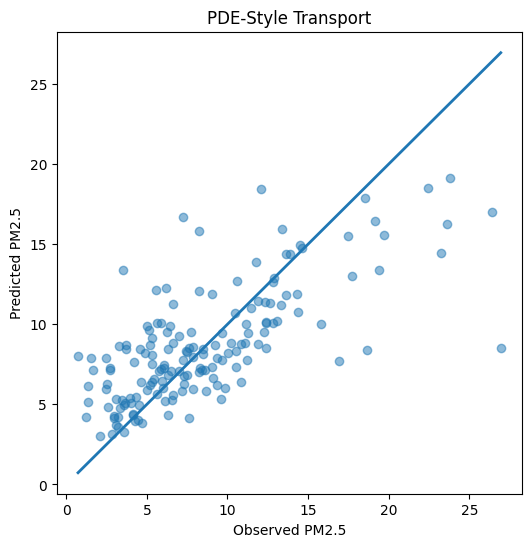

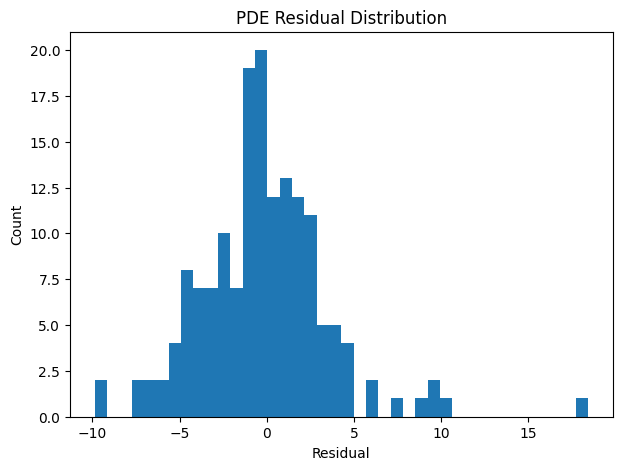

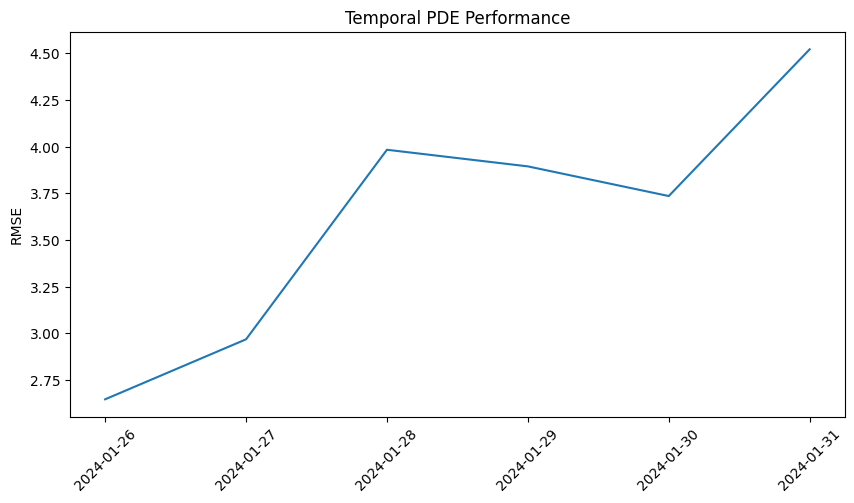


TRANSPORT REDUCTION EFFECT
-0.36221902058076033

COUNTY TRANSPORT
county_name
Butte              0.000000
Calaveras          6.658419
Colusa             7.029773
Fresno             6.930299
Imperial           8.857461
Inyo               4.118021
Kern               8.167592
Kings              7.626973
Los Angeles        7.202512
Madera             6.659672
Merced             6.408606
Mono               6.173007
Orange             8.201087
Placer             6.901022
Riverside          8.352018
Sacramento         6.709513
San Benito         7.340332
San Bernardino     7.602944
San Diego          9.020133
San Joaquin        6.479506
San Luis Obispo    8.233638
Santa Barbara      7.693308
Santa Clara        7.258026
Stanislaus         6.724294
Sutter             7.015984
Tulare             6.900096
Ventura            7.707073
Yolo               6.964525
Name: pde_spillover, dtype: float64


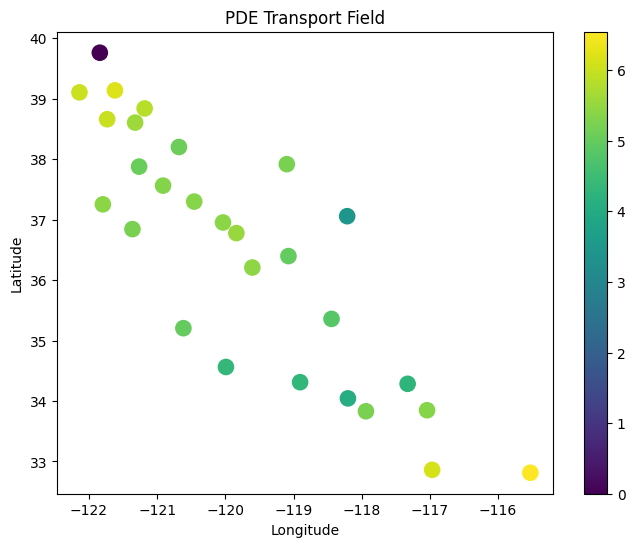


MODEL HIERARCHY
         Model          Description
0     Gaussian  Isotropic smoothing
1  Anisotropic   Directional kernel
2          PDE  Advection-diffusion

FILES SAVED


In [ ]:
 

import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_squared_error,
    r2_score
)

from scipy.spatial.distance import cdist

 

df = pd.read_csv(
    
    "epa_pm25_transport.csv"
)

coords_df = pd.read_csv(
    
    "county_coordinates.csv"
)

df = df.dropna()

 

county_order = coords_df[
    "county_name"
].values

coords = coords_df[
    [
        "longitude",
        "latitude"
    ]
].values

 

distance_matrix = cdist(
    
    coords,
    
    coords
)

 

direction_matrix = np.zeros(
    
    (
        len(coords),
        len(coords)
    )
)

for i in range(len(coords)):
    
    for j in range(len(coords)):
        
        dx = (
            
            coords[j,0]
            
            - 
            
            coords[i,0]
        )
        
        dy = (
            
            coords[j,1]
            
            - 
            
            coords[i,1]
        )
        
        direction_matrix[i,j] = np.arctan2(
            
            dy,
            
            dx
        )

 

def wind_to_angle(
    
    wind_speed
):
    
    # simplified transport direction
    
    return (
        
        np.pi/4
        
        + 
        
        0.01*wind_speed
    )

 

def pde_transport_kernel(
    
    distance,
    
    direction,
    
    wind_angle,
    
    wind_speed,
    
    diffusion = 0.5,
    
    sigma = 1.5
):
    
    gaussian_part = np.exp(
        
        -(distance**2) /
        
        (2*sigma**2)
    )
    
    directional_part = np.maximum(
        
        0,
        
        np.cos(
            
            direction
            
            -
            
            wind_angle
        )
    )
    
    advection_strength = (
        
        1
        
        + 
        
        diffusion
        
        * wind_speed
    )
    
    return (
        
        gaussian_part
        
        * directional_part
        
        * advection_strength
    )

 

pde_results = []

unique_dates = sorted(
    
    df["date_local"].unique()
)

for d in unique_dates:
    
    day_df = df[
        
        df["date_local"]
        
        ==
        
        d
    ]
    
    aligned = pd.DataFrame({
        
        "county_name":county_order
    })
    
    aligned = aligned.merge(
        
        day_df,
        
        on="county_name",
        
        how="left"
    )
    
    aligned = aligned.sort_values(
        "county_name"
    )
    
    pm = aligned[
        "pm25"
    ].values
    
    wind_speed = np.nanmean(
        
        aligned[
            "wind_speed"
        ].values
    )
    
    wind_angle = wind_to_angle(
        
        wind_speed
    )
    
    spill = np.zeros(
        len(pm)
    )
    
    for i in range(len(pm)):
        
        weights = pde_transport_kernel(
            
            distance_matrix[i],
            
            direction_matrix[i],
            
            wind_angle,
            
            wind_speed
        )
        
        weights[i] = 0
        
        weight_sum = np.nansum(
            weights
        )
        
        if weight_sum > 0:
            
            weights = (
                
                weights
                
                / weight_sum
            )
        
        spill[i] = np.nansum(
            
            weights
            
            * pm
        )
    
    aligned[
        "pde_spillover"
    ] = spill
    
    pde_results.append(
        aligned
    )

pde_df = pd.concat(
    
    pde_results
)

 
feature_cols = [

    "pm25_lag1",

    "pm25_lag2",

    "spillover",

    "pde_spillover",

    "wind_speed",

    "temperature"
]
pde_df = pde_df.dropna()

X = pde_df[
    feature_cols
].values

y = pde_df[
    "pm25"
].values

 

n = len(pde_df)

train_size = int(
    0.8 * n
)

X_train = X[:train_size]

X_test = X[train_size:]

y_train = y[:train_size]

y_test = y[train_size:]

 
pde_model = LinearRegression()

pde_model.fit(
    
    X_train,
    
    y_train
)

pred = pde_model.predict(
    
    X_test
)

 

rmse = np.sqrt(
    
    mean_squared_error(
        
        y_test,
        
        pred
    )
)

r2 = r2_score(
    
    y_test,
    
    pred
)

print("\nPDE TRANSPORT MODEL")

print("RMSE:", rmse)

print("R2:", r2)

 

coef_df = pd.DataFrame({
    
    "Feature":feature_cols,
    
    "Coefficient":
        pde_model.coef_
})

print("\nCOEFFICIENTS")

print(coef_df)

 

plt.figure(figsize=(6,6))

plt.scatter(
    
    y_test,
    
    pred,
    
    alpha=0.5
)

plt.plot(
    
    [
        y_test.min(),
        y_test.max()
    ],
    
    [
        y_test.min(),
        y_test.max()
    ],
    
    linewidth=2
)

plt.xlabel("Observed PM2.5")

plt.ylabel("Predicted PM2.5")

plt.title("PDE-Style Transport")

plt.show()

 

residuals = (
    
    y_test
    
    -
    
    pred
)

plt.figure(figsize=(7,5))

plt.hist(
    
    residuals,
    
    bins=40
)

plt.xlabel("Residual")

plt.ylabel("Count")

plt.title("PDE Residual Distribution")

plt.show()
 
time_rmse = []

dates_test = pde_df[
    "date_local"
].iloc[train_size:]

unique_test_dates = sorted(
    
    dates_test.unique()
)

for d in unique_test_dates:
    
    idx = (
        
        dates_test
        
        ==
        
        d
    )
    
    y_d = y_test[idx]
    
    pred_d = pred[idx]
    
    rmse_d = np.sqrt(
        
        mean_squared_error(
            
            y_d,
            
            pred_d
        )
    )
    
    time_rmse.append({
        
        "date":d,
        
        "rmse":rmse_d
    })

time_rmse = pd.DataFrame(
    time_rmse
)

 
plt.figure(figsize=(10,5))

plt.plot(
    
    time_rmse["date"],
    
    time_rmse["rmse"]
)

plt.xticks(rotation=45)

plt.ylabel("RMSE")

plt.title("Temporal PDE Performance")

plt.show()

 

counterfactual = X.copy()

# reduce PDE transport

counterfactual[:,4] = (
    
    counterfactual[:,4]
    
    * 0.5
)

counter_pred = pde_model.predict(
    
    counterfactual
)

policy_effect = np.mean(
    
    y
    
    -
    
    counter_pred
)

print("\nTRANSPORT REDUCTION EFFECT")

print(policy_effect)

 

county_transport = pde_df.groupby(
    
    "county_name"
)[
    "pde_spillover"
].mean()

print("\nCOUNTY TRANSPORT")

print(county_transport)

 

example_day = pde_df[
    
    pde_df["date_local"]
    
    ==
    
    pde_df["date_local"].iloc[0]
]

plt.figure(figsize=(8,6))

plt.scatter(
    
    coords[:,0],
    
    coords[:,1],
    
    c = example_day[
        "pde_spillover"
    ],
    
    s = 120
)

plt.colorbar()

plt.xlabel("Longitude")

plt.ylabel("Latitude")

plt.title("PDE Transport Field")

plt.show()

 

comparison = pd.DataFrame({
    
    "Model":[
        
        "Gaussian",
        
        "Anisotropic",
        
        "PDE"
    ],
    
    "Description":[
        
        "Isotropic smoothing",
        
        "Directional kernel",
        
        "Advection-diffusion"
    ]
})

print("\nMODEL HIERARCHY")

print(comparison)

 
 

coef_df.to_csv(
    
    "pde_transport_coefficients.csv",
    
    index=False
)

time_rmse.to_csv(
    
    "temporal_rmse.csv",
    
    index=False
)

pde_df.to_csv(
    
    "pde_transport_predictions.csv",
    
    index=False
)

comparison.to_csv(
    
    "transport_model_hierarchy.csv",
    
    index=False
)

print("\nFILES SAVED")

 

  county_name  date_local       pm25  pm25_lag1  pm25_lag2  spillover  \
0       Butte  2024-01-03   6.020834   9.041666  18.816667   5.707783   
1   Calaveras  2024-01-03   5.545454   5.647826   8.204166   5.993973   
2      Colusa  2024-01-03   7.274049  11.975000   6.673959   4.866218   
3      Fresno  2024-01-03   6.154816  14.259722  16.800000   7.330048   
4    Imperial  2024-01-03  13.918055   6.454167  11.497222   7.315705   

   wind_speed  temperature  isotropic_spillover  anisotropic_spillover  \
0   90.032292    45.605555             5.205919               0.000000   
1   79.631250    41.683333             5.019760               5.061260   
2   96.818750    47.778261             4.954014               6.020834   
3   99.992532    48.358333             4.693389               5.542087   
4  110.331250    53.416667             6.704756               6.543223   

   pde_spillover  
0       0.000000  
1       5.061260  
2       6.020834  
3       5.542087  
4       6.543223  

I

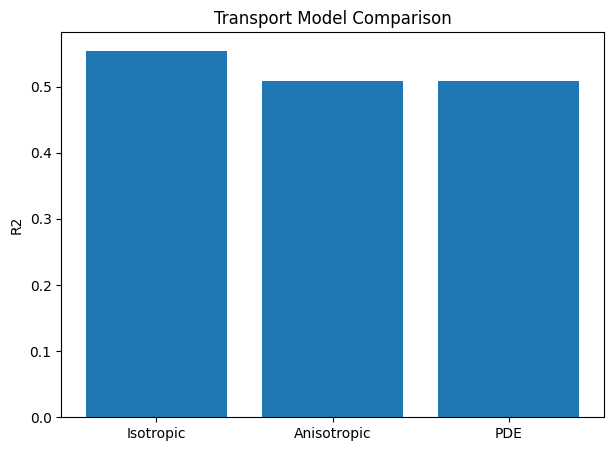


FILES SAVED


In [ ]:
 

import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

from scipy.spatial.distance import cdist

from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_squared_error,
    r2_score
)

from sklearn.model_selection import train_test_split

 

df = pd.read_csv(
    
    "epa_pm25_transport.csv"
)

coords_df = pd.read_csv(
    
    "county_coordinates.csv"
)

df = df.dropna()

 

county_order = coords_df[
    "county_name"
].values

coords = coords_df[
    [
        "longitude",
        "latitude"
    ]
].values

 

distance_matrix = cdist(
    
    coords,
    
    coords
)

 
direction_matrix = np.zeros(
    
    (
        len(coords),
        len(coords)
    )
)

for i in range(len(coords)):
    
    for j in range(len(coords)):
        
        dx = (
            
            coords[j,0]
            
            -
            
            coords[i,0]
        )
        
        dy = (
            
            coords[j,1]
            
            -
            
            coords[i,1]
        )
        
        direction_matrix[i,j] = np.arctan2(
            
            dy,
            
            dx
        )

 

def isotropic_kernel(
    
    distance,
    
    sigma = 1.5
):
    
    return np.exp(
        
        -(distance**2)
        
        /
        
        (2*sigma**2)
    )

 

def anisotropic_kernel(
    
    distance,
    
    direction,
    
    wind_angle,
    
    sigma = 1.5
):
    
    gaussian_part = np.exp(
        
        -(distance**2)
        
        /
        
        (2*sigma**2)
    )
    
    directional_part = np.maximum(
        
        0,
        
        np.cos(
            
            direction
            
            -
            
            wind_angle
        )
    )
    
    return (
        
        gaussian_part
        
        * directional_part
    )
 
 

def pde_kernel(
    
    distance,
    
    direction,
    
    wind_angle,
    
    wind_speed,
    
    sigma = 1.5,
    
    diffusion = 0.5
):
    
    gaussian_part = np.exp(
        
        -(distance**2)
        
        /
        
        (2*sigma**2)
    )
    
    directional_part = np.maximum(
        
        0,
        
        np.cos(
            
            direction
            
            -
            
            wind_angle
        )
    )
    
    advection = (
        
        1
        
        +
        
        diffusion
        
        * wind_speed
    )
    
    return (
        
        gaussian_part
        
        * directional_part
        
        * advection
    )
 

def wind_to_angle(
    
    wind_speed
):
    
    return (
        
        np.pi/4
        
        +
        
        0.01*wind_speed
    )
 

transport_results = []

unique_dates = sorted(
    
    df["date_local"].unique()
)

for d in unique_dates:
    
    day_df = df[
        
        df["date_local"]
        
        ==
        
        d
    ]
    
    aligned = pd.DataFrame({
        
        "county_name":county_order
    })
    
    aligned = aligned.merge(
        
        day_df,
        
        on="county_name",
        
        how="left"
    )
    
    aligned = aligned.sort_values(
        "county_name"
    )
    
    pm = aligned[
        "pm25"
    ].values
    
    wind_speed = np.nanmean(
        
        aligned[
            "wind_speed"
        ]
    )
    
    wind_angle = wind_to_angle(
        
        wind_speed
    )
    
    iso_spill = np.zeros(
        len(pm)
    )
    
    aniso_spill = np.zeros(
        len(pm)
    )
    
    pde_spill = np.zeros(
        len(pm)
    )
    
 
    
    for i in range(len(pm)):
        
   
        
        w_iso = isotropic_kernel(
            
            distance_matrix[i]
        )
        
        w_iso[i] = 0
        
        w_iso = (
            
            w_iso
            
            / np.nansum(w_iso)
        )
        
        iso_spill[i] = np.nansum(
            
            w_iso
            
            * pm
        )
        
   
        
        w_aniso = anisotropic_kernel(
            
            distance_matrix[i],
            
            direction_matrix[i],
            
            wind_angle
        )
        
        w_aniso[i] = 0
        
        aniso_sum = np.nansum(
            w_aniso
        )
        
        if aniso_sum > 0:
            
            w_aniso = (
                
                w_aniso
                
                / aniso_sum
            )
        
        aniso_spill[i] = np.nansum(
            
            w_aniso
            
            * pm
        )
        
 
        
        w_pde = pde_kernel(
            
            distance_matrix[i],
            
            direction_matrix[i],
            
            wind_angle,
            
            wind_speed
        )
        
        w_pde[i] = 0
        
        pde_sum = np.nansum(
            w_pde
        )
        
        if pde_sum > 0:
            
            w_pde = (
                
                w_pde
                
                / pde_sum
            )
        
        pde_spill[i] = np.nansum(
            
            w_pde
            
            * pm
        )
    
 
    
    aligned[
        "isotropic_spillover"
    ] = iso_spill
    
    aligned[
        "anisotropic_spillover"
    ] = aniso_spill
    
    aligned[
        "pde_spillover"
    ] = pde_spill
    
    transport_results.append(
        aligned
    )

 

transport_df = pd.concat(
    
    transport_results
)

transport_df = transport_df.dropna()

print(
    transport_df.head()
)

 
model_specs = {
    
    "Isotropic":[
        
        "pm25_lag1",
        
        "pm25_lag2",
        
        "isotropic_spillover",
        
        "wind_speed",
        
        "temperature"
    ],
    
    "Anisotropic":[
        
        "pm25_lag1",
        
        "pm25_lag2",
        
        "anisotropic_spillover",
        
        "wind_speed",
        
        "temperature"
    ],
    
    "PDE":[
        
        "pm25_lag1",
        
        "pm25_lag2",
        
        "pde_spillover",
        
        "wind_speed",
        
        "temperature"
    ]
}

 

results = []

 

for model_name, features in model_specs.items():
    
    X = transport_df[
        features
    ].values
    
    y = transport_df[
        "pm25"
    ].values
    
    X_train, X_test, y_train, y_test = train_test_split(
        
        X,
        
        y,
        
        test_size=0.2,
        
        random_state=123
    )
    
    model = LinearRegression()
    
    model.fit(
        
        X_train,
        
        y_train
    )
    
    pred = model.predict(
        X_test
    )
    
    rmse = np.sqrt(
        
        mean_squared_error(
            
            y_test,
            
            pred
        )
    )
    
    r2 = r2_score(
        
        y_test,
        
        pred
    )
    
    results.append({
        
        "Model":model_name,
        
        "RMSE":rmse,
        
        "R2":r2
    })
    
 
    
    print(model_name)
 
    print("RMSE:", rmse)
    
    print("R2:", r2)
    
    coef_df = pd.DataFrame({
        
        "Feature":features,
        
        "Coefficient":
            model.coef_
    })
    
    print(coef_df)
 

results_df = pd.DataFrame(
    results
)

print("\nFINAL COMPARISON")

print(results_df)

 

plt.figure(figsize=(7,5))

plt.bar(
    
    results_df["Model"],
    
    results_df["R2"]
)

plt.ylabel("R2")

plt.title("Transport Model Comparison")

plt.show()

 

results_df.to_csv(
    
    "transport_model_results.csv",
    
    index=False
)

transport_df.to_csv(
    
    "transport_full_dataset.csv",
    
    index=False
)

print("\nFILES SAVED")

 


TEMPORAL HOLDOUT
lag_only 3.922752378100826 0.44206501021792866
weather 4.039669791588207 0.40831093539128194
isotropic 3.9014203584163663 0.4481166380998062
anisotropic 3.985718189691365 0.42400994266531666
pde 3.9857181896913647 0.4240099426653168

SPATIAL HOLDOUT
lag_only 3.4911564149299577 -0.17944989320175678
weather 3.517709292602056 -0.28128544953007567
isotropic 3.212938195391161 -0.6071012811106712
anisotropic 3.340858053450458 -0.5451036283538561
pde 3.3408580534504586 -0.545103628353856

RANDOM FOREST
RF RMSE: 2.6160759162841956
RF R2: 0.654668212045808
         Feature  Importance
0      pm25_lag1    0.487541
2  pde_spillover    0.291730
4    temperature    0.074368
3     wind_speed    0.074010
1      pm25_lag2    0.072350

BOOTSTRAP
95% CI: [0.35580443 0.53863592]


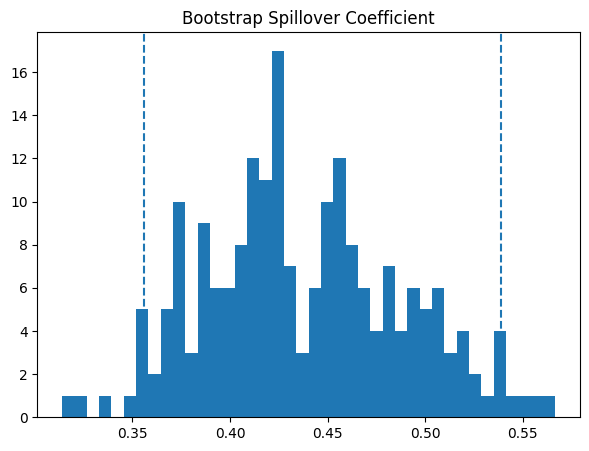


MORAN ANALYSIS
         Model   Moran_I
0     lag_only  0.018760
1      weather -0.020249
2    isotropic -0.016689
3  anisotropic -0.029264
4          pde -0.029264


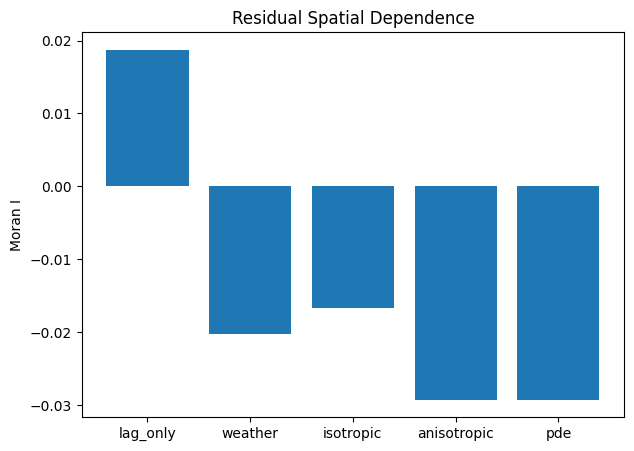


FINAL VALIDATION
  Validation        Model      RMSE        R2
0   Temporal     lag_only  3.922752  0.442065
1   Temporal      weather  4.039670  0.408311
2   Temporal    isotropic  3.901420  0.448117
3   Temporal  anisotropic  3.985718  0.424010
4   Temporal          pde  3.985718  0.424010
5    Spatial     lag_only  3.491156 -0.179450
6    Spatial      weather  3.517709 -0.281285
7    Spatial    isotropic  3.212938 -0.607101
8    Spatial  anisotropic  3.340858 -0.545104
9    Spatial          pde  3.340858 -0.545104

FILES SAVED


In [ ]:
 

import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression

from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_squared_error,
    r2_score
)

from sklearn.model_selection import (
    train_test_split,
    LeaveOneGroupOut
)

from scipy.spatial.distance import (
    pdist,
    squareform
)

 

df = pd.read_csv(
    
    "transport_full_dataset.csv"
)

coords_df = pd.read_csv(
    
    "county_coordinates.csv"
)

df = df.dropna()

 

feature_sets = {
    
    "lag_only":[
        
        "pm25_lag1",
        
        "pm25_lag2"
    ],
    
    "weather":[
        
        "pm25_lag1",
        
        "pm25_lag2",
        
        "wind_speed",
        
        "temperature"
    ],
    
    "isotropic":[
        
        "pm25_lag1",
        
        "pm25_lag2",
        
        "isotropic_spillover",
        
        "wind_speed",
        
        "temperature"
    ],
    
    "anisotropic":[
        
        "pm25_lag1",
        
        "pm25_lag2",
        
        "anisotropic_spillover",
        
        "wind_speed",
        
        "temperature"
    ],
    
    "pde":[
        
        "pm25_lag1",
        
        "pm25_lag2",
        
        "pde_spillover",
        
        "wind_speed",
        
        "temperature"
    ]
}

 

validation_results = []

  
df = df.sort_values(
    "date_local"
)

split_idx = int(
    0.8 * len(df)
)

train_df = df.iloc[:split_idx]

test_df = df.iloc[split_idx:]

for model_name, features in feature_sets.items():
    
    X_train = train_df[
        features
    ].values
    
    y_train = train_df[
        "pm25"
    ].values
    
    X_test = test_df[
        features
    ].values
    
    y_test = test_df[
        "pm25"
    ].values
    
    model = LinearRegression()
    
    model.fit(
        
        X_train,
        
        y_train
    )
    
    pred = model.predict(
        X_test
    )
    
    rmse = np.sqrt(
        
        mean_squared_error(
            
            y_test,
            
            pred
        )
    )
    
    r2 = r2_score(
        
        y_test,
        
        pred
    )
    
    validation_results.append({
        
        "Validation":"Temporal",
        
        "Model":model_name,
        
        "RMSE":rmse,
        
        "R2":r2
    })
    
    print(
        model_name,
        rmse,
        r2
    )

 
 

logo = LeaveOneGroupOut()

groups = df[
    "county_name"
].values

for model_name, features in feature_sets.items():
    
    X = df[
        features
    ].values
    
    y = df[
        "pm25"
    ].values
    
    rmses = []
    
    r2s = []
    
    for train_idx, test_idx in logo.split(
        
        X,
        
        y,
        
        groups
    ):
        
        X_train = X[train_idx]
        X_test = X[test_idx]
        
        y_train = y[train_idx]
        y_test = y[test_idx]
        
        model = LinearRegression()
        
        model.fit(
            
            X_train,
            
            y_train
        )
        
        pred = model.predict(
            X_test
        )
        
        rmses.append(
            
            np.sqrt(
                
                mean_squared_error(
                    
                    y_test,
                    
                    pred
                )
            )
        )
        
        r2s.append(
            
            r2_score(
                
                y_test,
                
                pred
            )
        )
    
    validation_results.append({
        
        "Validation":"Spatial",
        
        "Model":model_name,
        
        "RMSE":np.mean(rmses),
        
        "R2":np.mean(r2s)
    })
    
    print(
        model_name,
        np.mean(rmses),
        np.mean(r2s)
    )

 
rf_features = feature_sets["pde"]

X = df[
    rf_features
].values

y = df[
    "pm25"
].values

X_train, X_test, y_train, y_test = train_test_split(
    
    X,
    
    y,
    
    test_size=0.2,
    
    random_state=123
)

rf_model = RandomForestRegressor(
    
    n_estimators=200,
    
    max_depth=10,
    
    random_state=123
)

rf_model.fit(
    
    X_train,
    
    y_train
)

rf_pred = rf_model.predict(
    X_test
)

rf_rmse = np.sqrt(
    
    mean_squared_error(
        
        y_test,
        
        rf_pred
    )
)

rf_r2 = r2_score(
    
    y_test,
    
    rf_pred
)

print("RF RMSE:", rf_rmse)

print("RF R2:", rf_r2)

 

rf_importance = pd.DataFrame({
    
    "Feature":rf_features,
    
    "Importance":
        rf_model.feature_importances_
})

rf_importance = rf_importance.sort_values(
    
    "Importance",
    
    ascending=False
)

print(rf_importance)
 

boot_betas = []

features = feature_sets["pde"]

X = df[
    features
].values

y = df[
    "pm25"
].values

for b in range(200):
    
    idx = np.random.choice(
        
        len(df),
        
        size=len(df),
        
        replace=True
    )
    
    X_boot = X[idx]
    
    y_boot = y[idx]
    
    model = LinearRegression()
    
    model.fit(
        
        X_boot,
        
        y_boot
    )
    
    boot_betas.append(
        
        model.coef_[2]
    )

boot_betas = np.array(
    boot_betas
)

ci = np.percentile(
    
    boot_betas,
    
    [2.5,97.5]
)

print("95% CI:", ci)

 

plt.figure(figsize=(7,5))

plt.hist(
    
    boot_betas,
    
    bins=40
)

plt.axvline(
    
    ci[0],
    
    linestyle="--"
)

plt.axvline(
    
    ci[1],
    
    linestyle="--"
)

plt.title("Bootstrap Spillover Coefficient")

plt.show()

 

coords = coords_df[
    [
        "longitude",
        "latitude"
    ]
].values

dist_matrix = squareform(
    
    pdist(coords)
)

weights = 1 / (
    
    dist_matrix
    
    + 1e-5
)

np.fill_diagonal(
    
    weights,
    
    0
)

moran_results = []

for model_name, features in feature_sets.items():
    
    X = df[
        features
    ].values
    
    y = df[
        "pm25"
    ].values
    
    model = LinearRegression()
    
    model.fit(
        
        X,
        
        y
    )
    
    pred = model.predict(
        X
    )
    
    df[
        "resid"
    ] = y - pred
    
    county_resid = df.groupby(
        
        "county_name"
    )[
        "resid"
    ].mean().values
    
    resid_centered = (
        
        county_resid
        
        -
        
        county_resid.mean()
    )
    
    numerator = 0
    
    for i in range(len(county_resid)):
        
        for j in range(len(county_resid)):
            
            numerator += (
                
                weights[i,j]
                
                * resid_centered[i]
                
                * resid_centered[j]
            )
    
    denominator = np.sum(
        
        resid_centered**2
    )
    
    moran_I = (
        
        len(county_resid)
        
        /
        
        np.sum(weights)
        
        *
        
        numerator
        
        /
        
        denominator
    )
    
    moran_results.append({
        
        "Model":model_name,
        
        "Moran_I":moran_I
    })

moran_results = pd.DataFrame(
    moran_results
)

print(moran_results)

 

plt.figure(figsize=(7,5))

plt.bar(
    
    moran_results["Model"],
    
    moran_results["Moran_I"]
)

plt.ylabel("Moran I")

plt.title("Residual Spatial Dependence")

plt.show()

 
validation_results = pd.DataFrame(
    validation_results
)

print("\nFINAL VALIDATION")

print(validation_results)

 

validation_results.to_csv(
    
    "validation_results.csv",
    
    index=False
)

moran_results.to_csv(
    
    "moran_results.csv",
    
    index=False
)

rf_importance.to_csv(
    
    "rf_importance.csv",
    
    index=False
)

print("\nFILES SAVED")
 


TEMPORAL HOLDOUT
lag_only 3.922752378100826 0.44206501021792866
weather 4.039669791588207 0.40831093539128194
isotropic 3.9014203584163663 0.4481166380998062
anisotropic 3.985718189691365 0.42400994266531666
pde 3.9857181896913647 0.4240099426653168

SPATIAL HOLDOUT
lag_only 3.4911564149299577 -0.17944989320175678
weather 3.517709292602056 -0.28128544953007567
isotropic 3.212938195391161 -0.6071012811106712
anisotropic 3.340858053450458 -0.5451036283538561
pde 3.3408580534504586 -0.545103628353856

RANDOM FOREST
RF RMSE: 2.6160759162841956
RF R2: 0.654668212045808
         Feature  Importance
0      pm25_lag1    0.487541
2  pde_spillover    0.291730
4    temperature    0.074368
3     wind_speed    0.074010
1      pm25_lag2    0.072350

BOOTSTRAP
95% CI: [0.35171358 0.53297121]


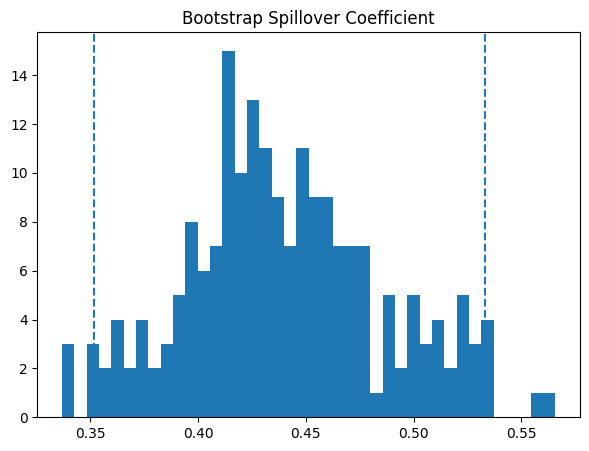


MORAN ANALYSIS
         Model   Moran_I
0     lag_only  0.018760
1      weather -0.020249
2    isotropic -0.016689
3  anisotropic -0.029264
4          pde -0.029264


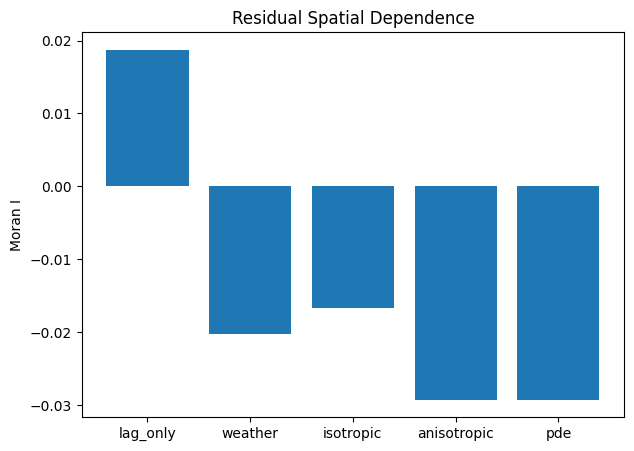


FINAL VALIDATION
  Validation        Model      RMSE        R2
0   Temporal     lag_only  3.922752  0.442065
1   Temporal      weather  4.039670  0.408311
2   Temporal    isotropic  3.901420  0.448117
3   Temporal  anisotropic  3.985718  0.424010
4   Temporal          pde  3.985718  0.424010
5    Spatial     lag_only  3.491156 -0.179450
6    Spatial      weather  3.517709 -0.281285
7    Spatial    isotropic  3.212938 -0.607101
8    Spatial  anisotropic  3.340858 -0.545104
9    Spatial          pde  3.340858 -0.545104

FILES SAVED


In [ ]:
 

import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression

from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_squared_error,
    r2_score
)

from sklearn.model_selection import (
    train_test_split,
    LeaveOneGroupOut
)

from scipy.spatial.distance import (
    pdist,
    squareform
)

 

df = pd.read_csv(
    
    "transport_full_dataset.csv"
)

coords_df = pd.read_csv(
    
    "county_coordinates.csv"
)

df = df.dropna()

 
feature_sets = {
    
    "lag_only":[
        
        "pm25_lag1",
        
        "pm25_lag2"
    ],
    
    "weather":[
        
        "pm25_lag1",
        
        "pm25_lag2",
        
        "wind_speed",
        
        "temperature"
    ],
    
    "isotropic":[
        
        "pm25_lag1",
        
        "pm25_lag2",
        
        "isotropic_spillover",
        
        "wind_speed",
        
        "temperature"
    ],
    
    "anisotropic":[
        
        "pm25_lag1",
        
        "pm25_lag2",
        
        "anisotropic_spillover",
        
        "wind_speed",
        
        "temperature"
    ],
    
    "pde":[
        
        "pm25_lag1",
        
        "pm25_lag2",
        
        "pde_spillover",
        
        "wind_speed",
        
        "temperature"
    ]
}

 

validation_results = []

 
 

df = df.sort_values(
    "date_local"
)

split_idx = int(
    0.8 * len(df)
)

train_df = df.iloc[:split_idx]

test_df = df.iloc[split_idx:]

for model_name, features in feature_sets.items():
    
    X_train = train_df[
        features
    ].values
    
    y_train = train_df[
        "pm25"
    ].values
    
    X_test = test_df[
        features
    ].values
    
    y_test = test_df[
        "pm25"
    ].values
    
    model = LinearRegression()
    
    model.fit(
        
        X_train,
        
        y_train
    )
    
    pred = model.predict(
        X_test
    )
    
    rmse = np.sqrt(
        
        mean_squared_error(
            
            y_test,
            
            pred
        )
    )
    
    r2 = r2_score(
        
        y_test,
        
        pred
    )
    
    validation_results.append({
        
        "Validation":"Temporal",
        
        "Model":model_name,
        
        "RMSE":rmse,
        
        "R2":r2
    })
    
    print(
        model_name,
        rmse,
        r2
    )
 

 

logo = LeaveOneGroupOut()

groups = df[
    "county_name"
].values

for model_name, features in feature_sets.items():
    
    X = df[
        features
    ].values
    
    y = df[
        "pm25"
    ].values
    
    rmses = []
    
    r2s = []
    
    for train_idx, test_idx in logo.split(
        
        X,
        
        y,
        
        groups
    ):
        
        X_train = X[train_idx]
        X_test = X[test_idx]
        
        y_train = y[train_idx]
        y_test = y[test_idx]
        
        model = LinearRegression()
        
        model.fit(
            
            X_train,
            
            y_train
        )
        
        pred = model.predict(
            X_test
        )
        
        rmses.append(
            
            np.sqrt(
                
                mean_squared_error(
                    
                    y_test,
                    
                    pred
                )
            )
        )
        
        r2s.append(
            
            r2_score(
                
                y_test,
                
                pred
            )
        )
    
    validation_results.append({
        
        "Validation":"Spatial",
        
        "Model":model_name,
        
        "RMSE":np.mean(rmses),
        
        "R2":np.mean(r2s)
    })
    
    print(
        model_name,
        np.mean(rmses),
        np.mean(r2s)
    )

 

rf_features = feature_sets["pde"]

X = df[
    rf_features
].values

y = df[
    "pm25"
].values

X_train, X_test, y_train, y_test = train_test_split(
    
    X,
    
    y,
    
    test_size=0.2,
    
    random_state=123
)

rf_model = RandomForestRegressor(
    
    n_estimators=200,
    
    max_depth=10,
    
    random_state=123
)

rf_model.fit(
    
    X_train,
    
    y_train
)

rf_pred = rf_model.predict(
    X_test
)

rf_rmse = np.sqrt(
    
    mean_squared_error(
        
        y_test,
        
        rf_pred
    )
)

rf_r2 = r2_score(
    
    y_test,
    
    rf_pred
)

print("RF RMSE:", rf_rmse)

print("RF R2:", rf_r2)
 
rf_importance = pd.DataFrame({
    
    "Feature":rf_features,
    
    "Importance":
        rf_model.feature_importances_
})

rf_importance = rf_importance.sort_values(
    
    "Importance",
    
    ascending=False
)

print(rf_importance)

 

boot_betas = []

features = feature_sets["pde"]

X = df[
    features
].values

y = df[
    "pm25"
].values

for b in range(200):
    
    idx = np.random.choice(
        
        len(df),
        
        size=len(df),
        
        replace=True
    )
    
    X_boot = X[idx]
    
    y_boot = y[idx]
    
    model = LinearRegression()
    
    model.fit(
        
        X_boot,
        
        y_boot
    )
    
    boot_betas.append(
        
        model.coef_[2]
    )

boot_betas = np.array(
    boot_betas
)

ci = np.percentile(
    
    boot_betas,
    
    [2.5,97.5]
)

print("95% CI:", ci)

 

plt.figure(figsize=(7,5))

plt.hist(
    
    boot_betas,
    
    bins=40
)

plt.axvline(
    
    ci[0],
    
    linestyle="--"
)

plt.axvline(
    
    ci[1],
    
    linestyle="--"
)

plt.title("Bootstrap Spillover Coefficient")

plt.show()

 

coords = coords_df[
    [
        "longitude",
        "latitude"
    ]
].values

dist_matrix = squareform(
    
    pdist(coords)
)

weights = 1 / (
    
    dist_matrix
    
    + 1e-5
)

np.fill_diagonal(
    
    weights,
    
    0
)

moran_results = []

for model_name, features in feature_sets.items():
    
    X = df[
        features
    ].values
    
    y = df[
        "pm25"
    ].values
    
    model = LinearRegression()
    
    model.fit(
        
        X,
        
        y
    )
    
    pred = model.predict(
        X
    )
    
    df[
        "resid"
    ] = y - pred
    
    county_resid = df.groupby(
        
        "county_name"
    )[
        "resid"
    ].mean().values
    
    resid_centered = (
        
        county_resid
        
        -
        
        county_resid.mean()
    )
    
    numerator = 0
    
    for i in range(len(county_resid)):
        
        for j in range(len(county_resid)):
            
            numerator += (
                
                weights[i,j]
                
                * resid_centered[i]
                
                * resid_centered[j]
            )
    
    denominator = np.sum(
        
        resid_centered**2
    )
    
    moran_I = (
        
        len(county_resid)
        
        /
        
        np.sum(weights)
        
        *
        
        numerator
        
        /
        
        denominator
    )
    
    moran_results.append({
        
        "Model":model_name,
        
        "Moran_I":moran_I
    })

moran_results = pd.DataFrame(
    moran_results
)

print(moran_results)

 

plt.figure(figsize=(7,5))

plt.bar(
    
    moran_results["Model"],
    
    moran_results["Moran_I"]
)

plt.ylabel("Moran I")

plt.title("Residual Spatial Dependence")

plt.show()

 

validation_results = pd.DataFrame(
    validation_results
)

print("\nFINAL VALIDATION")

print(validation_results)

 
validation_results.to_csv(
    
    "validation_results.csv",
    
    index=False
)

moran_results.to_csv(
    
    "moran_results.csv",
    
    index=False
)

rf_importance.to_csv(
    
    "rf_importance.csv",
    
    index=False
)

print("\nFILES SAVED")

 

               Transport             Model      RMSE        R2   Runtime
0    isotropic_spillover            Linear  3.283433  0.554594  0.003040
1    isotropic_spillover      RandomForest  2.927723  0.645872  1.096682
2    isotropic_spillover  GradientBoosting  3.052583  0.615023  0.671676
3  anisotropic_spillover            Linear  3.446070  0.509377  0.000998
4  anisotropic_spillover      RandomForest  3.000767  0.627982  1.175668
5  anisotropic_spillover  GradientBoosting  3.037220  0.618888  0.800177
6          pde_spillover            Linear  3.446070  0.509377  0.002000
7          pde_spillover      RandomForest  3.000767  0.627982  1.184651
8          pde_spillover  GradientBoosting  3.037220  0.618888  0.691619


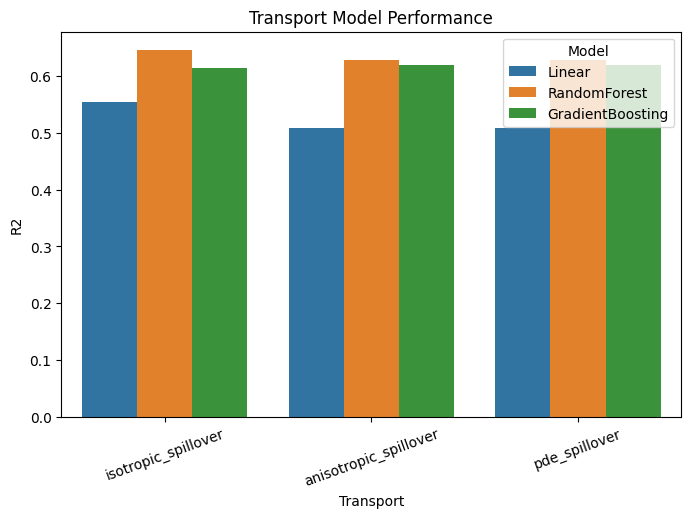

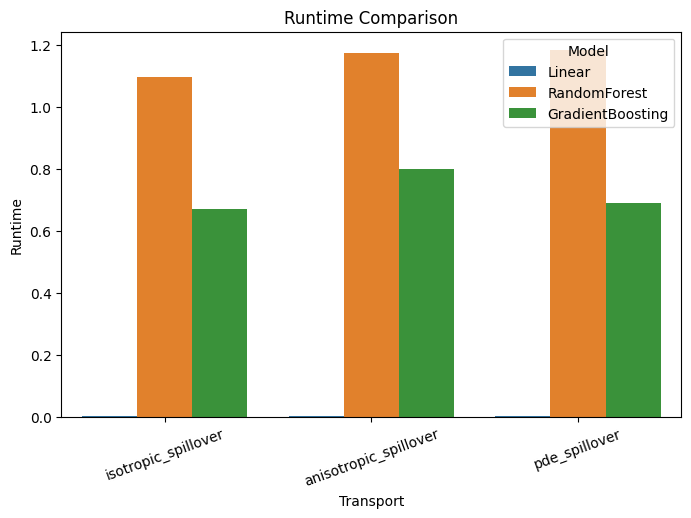

   Month        R2     RMSE
0      1  0.509377  3.44607


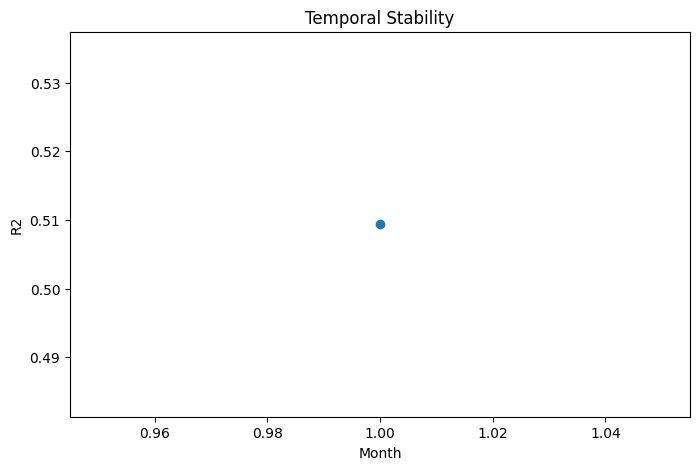

             County        R2      RMSE
0             Butte -0.360851  5.201545
1         Calaveras -0.032982  1.910843
2            Colusa -0.167009  2.404521
3            Fresno  0.880151  1.732339
4          Imperial  0.386138  7.046540
5              Inyo -0.003792  2.224682
6              Kern  0.425976  3.563558
7             Kings  0.888879  2.559822
8       Los Angeles -0.232410  2.964185
9            Madera  0.778179  1.739738
10           Merced  0.183296  4.509197
11             Mono -0.842396  1.565791
12           Orange -0.841049  3.378015
13           Placer  0.542938  1.684038
14        Riverside  0.179326  2.324755
15       Sacramento  0.340932  2.253048
16       San Benito  0.096681  2.260221
17   San Bernardino -2.152763  1.670696
18        San Diego  0.500172  1.668391
19      San Joaquin  0.784575  2.738879
20  San Luis Obispo  0.381825  0.479523
21    Santa Barbara -3.092309  0.944561
22      Santa Clara  0.411944  1.910606
23       Stanislaus  0.723906  3.104229


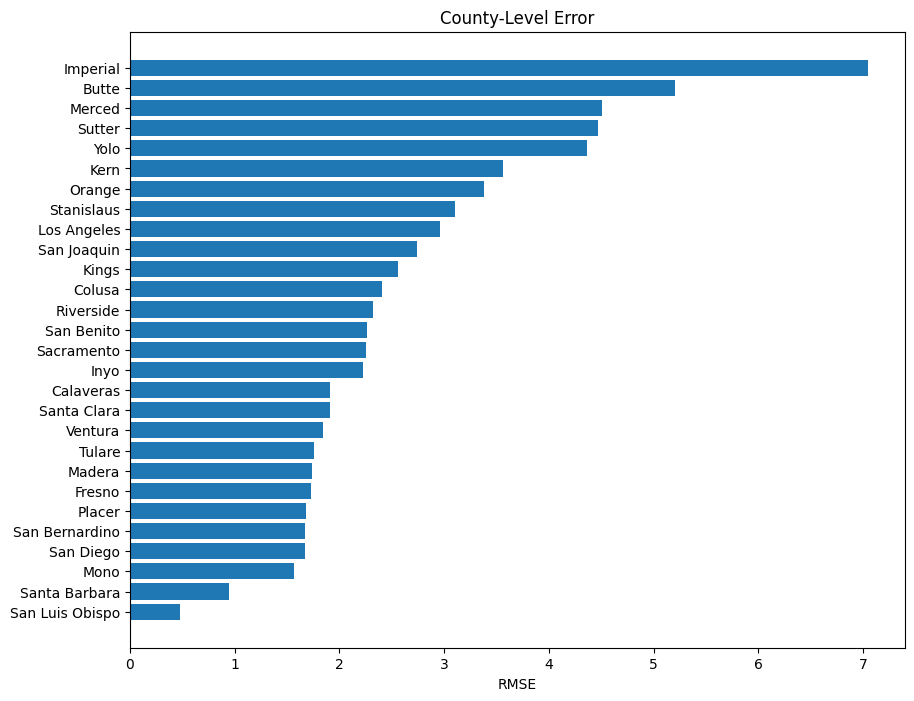


POLICY EFFECT
0.7741650865203862

EXTREME EVENTS
(40, 12)
Extreme Event R2: -1.0078512886314277

PUBLICATION TABLE
Model                  GradientBoosting    Linear  RandomForest
Transport                                                      
anisotropic_spillover          0.618888  0.509377      0.627982
isotropic_spillover            0.615023  0.554594      0.645872
pde_spillover                  0.618888  0.509377      0.627982

ALL FILES SAVED


In [ ]:
 
import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

import seaborn as sns

import time

from sklearn.linear_model import LinearRegression

from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

from sklearn.metrics import (
    mean_squared_error,
    r2_score
)

from sklearn.model_selection import (
    train_test_split
)
 

df = pd.read_csv(
    
    "transport_full_dataset.csv"
)

df = df.dropna()

 
base_features = [
    
    "pm25_lag1",
    
    "pm25_lag2",
    
    "wind_speed",
    
    "temperature"
]

transport_features = [
    
    "isotropic_spillover",
    
    "anisotropic_spillover",
    
    "pde_spillover"
]

 

master_results = []

 

model_dict = {
    
    "Linear":
        LinearRegression(),
    
    "RandomForest":
        RandomForestRegressor(
            n_estimators=200,
            max_depth=10,
            random_state=123
        ),
    
    "GradientBoosting":
        GradientBoostingRegressor(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=4,
            random_state=123
        )
}

 

for transport in transport_features:
    
    features = (
        
        base_features
        
        +
        
        [transport]
    )
    
    X = df[
        features
    ].values
    
    y = df[
        "pm25"
    ].values
    
    X_train, X_test, y_train, y_test = train_test_split(
        
        X,
        
        y,
        
        test_size=0.2,
        
        random_state=123
    )
    
    for model_name, model in model_dict.items():
        
        start_time = time.time()
        
        model.fit(
            
            X_train,
            
            y_train
        )
        
        pred = model.predict(
            X_test
        )
        
        runtime = (
            
            time.time()
            
            -
            
            start_time
        )
        
        rmse = np.sqrt(
            
            mean_squared_error(
                
                y_test,
                
                pred
            )
        )
        
        r2 = r2_score(
            
            y_test,
            
            pred
        )
        
        master_results.append({
            
            "Transport":transport,
            
            "Model":model_name,
            
            "RMSE":rmse,
            
            "R2":r2,
            
            "Runtime":runtime
        })

master_results = pd.DataFrame(
    master_results
)

print(master_results)

 

plt.figure(figsize=(8,5))

sns.barplot(
    
    data=master_results,
    
    x="Transport",
    
    y="R2",
    
    hue="Model"
)

plt.title("Transport Model Performance")

plt.xticks(rotation=20)

plt.show()

 

plt.figure(figsize=(8,5))

sns.barplot(
    
    data=master_results,
    
    x="Transport",
    
    y="Runtime",
    
    hue="Model"
)

plt.title("Runtime Comparison")

plt.xticks(rotation=20)

plt.show()

 

df["month"] = pd.to_datetime(
    
    df["date_local"]
).dt.month

monthly_results = []

for month in sorted(df["month"].unique()):
    
    month_df = df[
        
        df["month"]
        
        ==
        
        month
    ]
    
    features = [
        
        "pm25_lag1",
        
        "pm25_lag2",
        
        "pde_spillover",
        
        "wind_speed",
        
        "temperature"
    ]
    
    X = month_df[
        features
    ].values
    
    y = month_df[
        "pm25"
    ].values
    
    if len(month_df) < 30:
        
        continue
    
    X_train, X_test, y_train, y_test = train_test_split(
        
        X,
        
        y,
        
        test_size=0.2,
        
        random_state=123
    )
    
    model = LinearRegression()
    
    model.fit(
        
        X_train,
        
        y_train
    )
    
    pred = model.predict(
        X_test
    )
    
    monthly_results.append({
        
        "Month":month,
        
        "R2":
            r2_score(
                y_test,
                pred
            ),
        
        "RMSE":
            np.sqrt(
                mean_squared_error(
                    y_test,
                    pred
                )
            )
    })

monthly_results = pd.DataFrame(
    monthly_results
)

print(monthly_results)

 

plt.figure(figsize=(8,5))

plt.plot(
    
    monthly_results["Month"],
    
    monthly_results["R2"],
    
    marker="o"
)

plt.xlabel("Month")

plt.ylabel("R2")

plt.title("Temporal Stability")

plt.show()

 

county_results = []

counties = df[
    "county_name"
].unique()

for county in counties:
    
    county_df = df[
        
        df["county_name"]
        
        ==
        
        county
    ]
    
    if len(county_df) < 20:
        
        continue
    
    features = [
        
        "pm25_lag1",
        
        "pm25_lag2",
        
        "pde_spillover",
        
        "wind_speed",
        
        "temperature"
    ]
    
    X = county_df[
        features
    ].values
    
    y = county_df[
        "pm25"
    ].values
    
    X_train, X_test, y_train, y_test = train_test_split(
        
        X,
        
        y,
        
        test_size=0.2,
        
        random_state=123
    )
    
    model = LinearRegression()
    
    model.fit(
        
        X_train,
        
        y_train
    )
    
    pred = model.predict(
        X_test
    )
    
    county_results.append({
        
        "County":county,
        
        "R2":
            r2_score(
                y_test,
                pred
            ),
        
        "RMSE":
            np.sqrt(
                mean_squared_error(
                    y_test,
                    pred
                )
            )
    })

county_results = pd.DataFrame(
    county_results
)

print(county_results)

 

county_results = county_results.sort_values(
    
    "RMSE"
)

plt.figure(figsize=(10,8))

plt.barh(
    
    county_results["County"],
    
    county_results["RMSE"]
)

plt.xlabel("RMSE")

plt.title("County-Level Error")

plt.show()

 

features = [
    
    "pm25_lag1",
    
    "pm25_lag2",
    
    "pde_spillover",
    
    "wind_speed",
    
    "temperature"
]

X = df[
    features
].values

y = df[
    "pm25"
].values

model = LinearRegression()

model.fit(
    
    X,
    
    y
)

counterfactual = X.copy()

# reduce transport 25%

counterfactual[:,2] = (
    
    counterfactual[:,2]
    
    * 0.75
)

counter_pred = model.predict(
    
    counterfactual
)

policy_effect = np.mean(
    
    y
    
    -
    
    counter_pred
)

print("\nPOLICY EFFECT")

print(policy_effect)

 

threshold = df[
    "pm25"
].quantile(0.95)

extreme_df = df[
    
    df["pm25"]
    
    >=
    
    threshold
]

print("\nEXTREME EVENTS")

print(extreme_df.shape)

features = [
    
    "pm25_lag1",
    
    "pm25_lag2",
    
    "pde_spillover",
    
    "wind_speed",
    
    "temperature"
]

X = extreme_df[
    features
].values

y = extreme_df[
    "pm25"
].values

if len(extreme_df) > 30:
    
    X_train, X_test, y_train, y_test = train_test_split(
        
        X,
        
        y,
        
        test_size=0.2,
        
        random_state=123
    )
    
    model = LinearRegression()
    
    model.fit(
        
        X_train,
        
        y_train
    )
    
    pred = model.predict(
        X_test
    )
    
    print(
        "Extreme Event R2:",
        r2_score(
            y_test,
            pred
        )
    )

 

publication_table = master_results.pivot_table(
    
    index="Transport",
    
    columns="Model",
    
    values="R2"
)

print("\nPUBLICATION TABLE")

print(publication_table)

 

master_results.to_csv(
    
    "master_results.csv",
    
    index=False
)

monthly_results.to_csv(
    
    "monthly_results.csv",
    
    index=False
)

county_results.to_csv(
    
    "county_results.csv",
    
    index=False
)

publication_table.to_csv(
    
    "publication_table.csv"
)

print("\nALL FILES SAVED")

  

NameError: name 'weak_sigma' is not defined

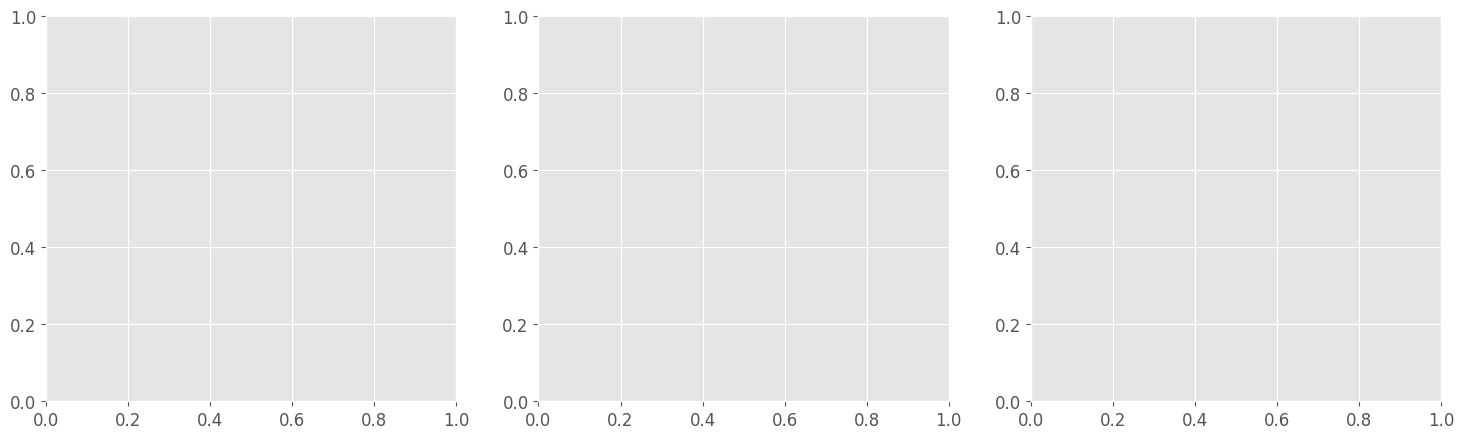

In [ ]:
 

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np

 

plt.style.use("ggplot")

plt.rcParams.update({
    
    "font.size": 12,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "figure.titlesize": 18,
    "legend.fontsize": 11
})

 

fig1, axes = plt.subplots(
    
    1,
    3,
    
    figsize=(18,5)
)

 
axes[0].plot(
    
    weak_sigma,
    weak_beta_bias,
    
    marker="o",
    linewidth=2
)

axes[0].axhline(
    
    0,
    
    linestyle="--",
    
    color="red"
)

axes[0].set_title(
    
    "Weak Transport"
)

axes[0].set_xlabel(
    
    r"$\sigma$"
)

axes[0].set_ylabel(
    
    r"$\beta_2$ Bias"
)

 

axes[1].plot(
    
    gaussian_sigma,
    gaussian_beta_bias,
    
    marker="o",
    linewidth=2
)

axes[1].axhline(
    
    0,
    
    linestyle="--",
    
    color="red"
)

axes[1].set_title(
    
    "Gaussian-like Transport"
)

axes[1].set_xlabel(
    
    r"$\sigma$"
)

axes[1].set_ylabel(
    
    r"$\beta_2$ Bias"
)
 
axes[2].plot(
    
    strong_sigma,
    strong_beta_bias,
    
    marker="o",
    linewidth=2
)

axes[2].axhline(
    
    0,
    
    linestyle="--",
    
    color="red"
)

axes[2].set_title(
    
    "Strong Directional Transport"
)

axes[2].set_xlabel(
    
    r"$\sigma$"
)

axes[2].set_ylabel(
    
    r"$\beta_2$ Bias"
)

 

panel_labels = ["A","B","C"]

for ax, lab in zip(axes, panel_labels):
    
    ax.text(
        
        -0.15,
        1.05,
        
        lab,
        
        transform=ax.transAxes,
        
        fontsize=18,
        
        fontweight="bold"
    )

fig1.suptitle(
    
    "Spillover Coefficient Bias Under Transport Misspecification"
)

plt.tight_layout()

plt.savefig(
    
    "Figure1_Bias_Panels.png",
    
    dpi=600,
    
    bbox_inches="tight"
)

plt.savefig(
    
    "Figure1_Bias_Panels.pdf",
    
    bbox_inches="tight"
)

 

fig2, axes = plt.subplots(
    
    1,
    3,
    
    figsize=(18,5)
)

 

axes[0].plot(
    
    sigma_values,
    directional_condition,
    
    marker="o",
    linewidth=2
)

axes[0].set_title(
    
    "Directional Transport"
)

axes[0].set_xlabel(
    
    r"$\sigma$"
)

axes[0].set_ylabel(
    
    "Condition Number"
)

 

axes[1].plot(
    
    sigma_values,
    gaussian_condition,
    
    marker="o",
    linewidth=2
)

axes[1].set_title(
    
    "Gaussian-like Transport"
)

axes[1].set_xlabel(
    
    r"$\sigma$"
)

axes[1].set_ylabel(
    
    "Condition Number"
)

 

axes[2].plot(
    
    sigma_values,
    weak_condition,
    
    marker="o",
    linewidth=2
)

axes[2].set_title(
    
    "Weak Transport"
)

axes[2].set_xlabel(
    
    r"$\sigma$"
)

axes[2].set_ylabel(
    
    "Condition Number"
)

 

for ax, lab in zip(axes, panel_labels):
    
    ax.text(
        
        -0.15,
        1.05,
        
        lab,
        
        transform=ax.transAxes,
        
        fontsize=18,
        
        fontweight="bold"
    )

fig2.suptitle(
    
    "Numerical Instability Across Transport Operators"
)

plt.tight_layout()

plt.savefig(
    
    "Figure2_Condition_Number.png",
    
    dpi=600,
    
    bbox_inches="tight"
)

plt.savefig(
    
    "Figure2_Condition_Number.pdf",
    
    bbox_inches="tight"
)

 

fig3, axes = plt.subplots(
    
    1,
    3,
    
    figsize=(18,5)
)

 

axes[0].scatter(
    
    local_exposure,
    gaussian_spillover,
    
    alpha=0.35,
    
    s=25
)

axes[0].set_title(
    
    "Local vs Gaussian Spillover"
)

axes[0].set_xlabel(
    
    "Local Exposure"
)

axes[0].set_ylabel(
    
    "Gaussian Spillover"
)

 

axes[1].scatter(
    
    local_exposure,
    true_spillover,
    
    alpha=0.35,
    
    s=25
)

axes[1].set_title(
    
    "Local vs True Spillover"
)

axes[1].set_xlabel(
    
    "Local Exposure"
)

axes[1].set_ylabel(
    
    "True Spillover"
)

 

im = axes[2].imshow(
    
    gaussian_mapping,
    
    aspect="auto"
)

axes[2].set_title(
    
    "Gaussian Spillover Mapping"
)

plt.colorbar(
    
    im,
    
    ax=axes[2],
    
    fraction=0.046
)
 

for ax, lab in zip(axes, panel_labels):
    
    ax.text(
        
        -0.15,
        1.05,
        
        lab,
        
        transform=ax.transAxes,
        
        fontsize=18,
        
        fontweight="bold"
    )

fig3.suptitle(
    
    "Spillover Mapping Diagnostics"
)

plt.tight_layout()

plt.savefig(
    
    "Figure3_Spillover_Diagnostics.png",
    
    dpi=600,
    
    bbox_inches="tight"
)

plt.savefig(
    
    "Figure3_Spillover_Diagnostics.pdf",
    
    bbox_inches="tight"
)
 

fig4, axes = plt.subplots(
    
    1,
    3,
    
    figsize=(18,5)
)

 

im1 = axes[0].imshow(
    
    pollution_sources,
    
    aspect="auto"
)

axes[0].set_title(
    
    "Initial Pollution Sources"
)

plt.colorbar(
    
    im1,
    
    ax=axes[0],
    
    fraction=0.046
)

 

im2 = axes[1].imshow(
    
    transported_field,
    
    aspect="auto"
)

axes[1].set_title(
    
    "Transported Pollution Field"
)

plt.colorbar(
    
    im2,
    
    ax=axes[1],
    
    fraction=0.046
)

 

im3 = axes[2].imshow(
    
    gaussian_mapping,
    
    aspect="auto"
)

axes[2].set_title(
    
    "Gaussian Spillover Mapping"
)

plt.colorbar(
    
    im3,
    
    ax=axes[2],
    
    fraction=0.046
)

 

for ax, lab in zip(axes, panel_labels):
    
    ax.text(
        
        -0.15,
        1.05,
        
        lab,
        
        transform=ax.transAxes,
        
        fontsize=18,
        
        fontweight="bold"
    )

fig4.suptitle(
    
    "PDE-Based Transport Simulations"
)

plt.tight_layout()

plt.savefig(
    
    "Figure4_PDE_Transport.png",
    
    dpi=600,
    
    bbox_inches="tight"
)

plt.savefig(
    
    "Figure4_PDE_Transport.pdf",
    
    bbox_inches="tight"
)

 

fig5 = plt.figure(
    
    figsize=(18,10)
)

gs = gridspec.GridSpec(
    
    2,
    3
)

 

ax1 = fig5.add_subplot(gs[0,0])

ax1.scatter(
    
    predicted_pm25,
    observed_pm25,
    
    alpha=0.4
)

ax1.plot(
    
    [predicted_pm25.min(), predicted_pm25.max()],
    [predicted_pm25.min(), predicted_pm25.max()],
    
    color="red",
    
    linewidth=2
)

ax1.set_title(
    
    "Observed vs Predicted"
)

 

ax2 = fig5.add_subplot(gs[0,1])

ax2.scatter(
    
    predicted_pm25,
    residuals,
    
    alpha=0.4
)

ax2.axhline(
    
    0,
    
    linestyle="--",
    
    color="red"
)

ax2.set_title(
    
    "Residuals vs Fitted"
)

 

ax3 = fig5.add_subplot(gs[0,2])

ax3.hist(
    
    residuals,
    
    bins=30
)

ax3.set_title(
    
    "Residual Distribution"
)

 

ax4 = fig5.add_subplot(gs[1,0])

ax4.scatter(
    
    gaussian_spillover,
    observed_pm25,
    
    alpha=0.4
)

ax4.set_title(
    
    "Gaussian Spillover vs PM2.5"
)

 
ax5 = fig5.add_subplot(gs[1,1])

ax5.plot(
    
    dates,
    moran_values,
    
    marker="o"
)

ax5.axhline(
    
    0,
    
    linestyle="--",
    
    color="red"
)

ax5.set_title(
    
    "Residual Moran's I"
)
 

ax6 = fig5.add_subplot(gs[1,2])

ax6.plot(
    
    sigma_grid,
    r2_values,
    
    marker="o"
)

ax6.set_title(
    
    r"$R^2$ Sensitivity to $\sigma$"
)

 

all_axes = [ax1,ax2,ax3,ax4,ax5,ax6]

labels = ["A","B","C","D","E","F"]

for ax, lab in zip(all_axes, labels):
    
    ax.text(
        
        -0.15,
        1.05,
        
        lab,
        
        transform=ax.transAxes,
        
        fontsize=18,
        
        fontweight="bold"
    )

fig5.suptitle(
    
    "California PM2.5 Spillover Model Diagnostics"
)

plt.tight_layout()

plt.savefig(
    
    "Figure5_California_Results.png",
    
    dpi=600,
    
    bbox_inches="tight"
)

plt.savefig(
    
    "Figure5_California_Results.pdf",
    
    bbox_inches="tight"
)

 

print(
    
    "\nAll multi-panel figures saved.\n"
)